# Report: Modern Machine Learning in Practice - Group 26\n

### Kaggle Groupname: [26]

### Members:\n",
- Luca Agostini (168944)
- Arwin Koen S Gorissen (169097)
- Philipp Josef Nimphius (169243)


## Introduction
SINTEF is an independent research organization headquartered in Trondheim that researches hydropower among other things. The Tokke-Vinje watercourse is a system comprising 14 generating units in 9 power plants connected to 17 reservoirs by a web of rivers in Norway's Tokke and Vinje municipalities. SINTEF published a dataset containing the Unit Commitment decisions of hydropower plants from 2015 to 2026, along with other relevant data that was used in making these UC decisions. (https://snl.no/SINTEF , https://data.sintef.no/product/dp-df280e4c-09c8-49a4-aef9-5f9f1133c500 ) The aim of this project is to use machine learning to predict the UC decisions from the input data, and to speed up the decision process relative to using mathematical optimization methods. The model is created using the data from 2015-01-01 to 2023-01-01 and tested using the data from 2023-01-01 to 2024-12-25. The data was examined first through Exploratory Data Analysis to inform model decisions and help guide feature engineering. Through feature engineering, additional relations between features or patterns and combinations, and their correlation to the output decisions were explored. This allowed for the creation of a linear model that was able to capture deeper patterns and relations, that were not easily benefited from by only using the raw input data. After that, multiple types of models were considered and tested, before finally choosing and optimizing one through hyperparameter tuning. Finally, the effectiveness of the model and its features were interpreted and evaluated.

## Exploratory Data Analysis
EDA was performed on both the data in the core dataset as well as the data in the extended dataset to gain an understanding and an overview of the problem as well as the relevant variables. Each variable was examined separately first and plotted as a function of time to visualize the data and possibly reveal anomalies, patterns or trends to research further. This notebook contains a small selection of relevant plots to illustrate certain points discussed in the text. Through the EDA, the data was determined not to be majorly corrupted nor missing significant amounts of entries, and as a result no further cleanup was performed. The only data ananomaly found was that starting on the 30.09.2025 at 22:00 to 22:15 the day-ahead price data changed from 1 hour to 15 minute intervals (https://www.nve.no/reguleringsmyndigheten/regulering/regelverk-og-hoeringer/hoeringer/hoeringer-reguleringsmyndigheten-for-energi-rme/hoering-faktureringsmodell-for-sluttbrukere). However as the relevant timeframe of this project ranges from 01.01.2015 to 31.12.2024 our model is not affected by that and we do not need to account for that. Additionally according to the source of the data "These datasets are further processed and quality‑assured by SINTEF Energy Research" (https://data.sintef.no/product/dp-df280e4c-09c8-49a4-aef9-5f9f1133c500).

Prices were found to be quite volatile, and large spikes in later years were also discovered. These findings are in accordance with the factual spikes in energy prices recorded at that time as a result of geopolitical events, and lower than average precipitation in southern Norway. (https://www.ssb.no/en/energi-og-industri/energi/statistikk/elektrisitetspriser/article-for-electricity-prices/record-high-electricity-price-in-2022--curbed-by-electricity-support-for-households , https://www.sciencedirect.com/science/article/pii/S2666955223000357) Trends and seasonalities were also checked, resulting in the same peeks and suggesting the use of normalized and ranked features for training the model.

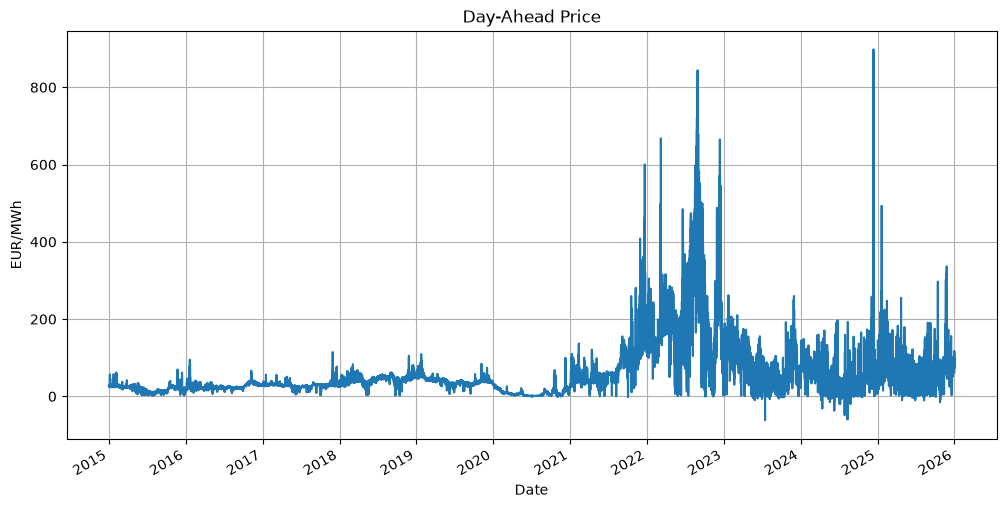

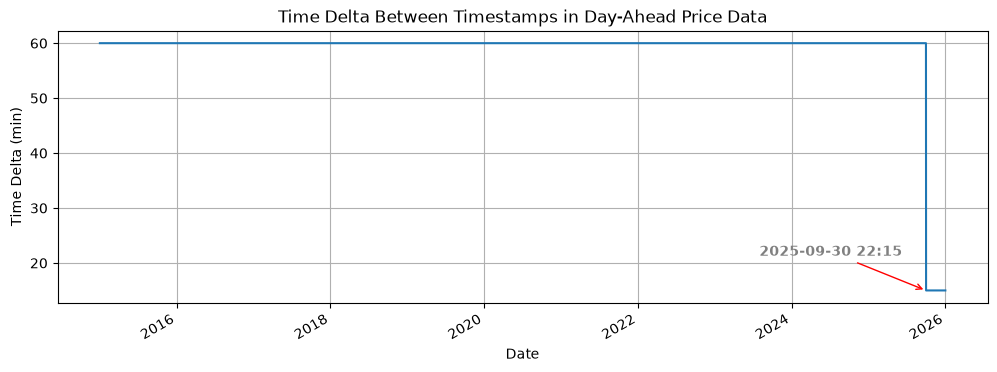

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import numpy as np
df = pd.read_csv("sintef_project/data/kernel/Historical_day_ahead_price_2015_2025.csv", parse_dates=["date"], index_col="date")
price = df["Day-ahead price (EUR/MWh)"]
ax = price.plot(figsize=(12, 6))
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Day-Ahead Price")
ax.set_ylabel("EUR/MWh")
ax.set_xlabel("Date")
ax.grid(True)
plt.show()

dt = df.index.to_series().diff().dt.total_seconds().div(60).dropna()
edge = dt.index[dt.diff() < 0][0]
ax = dt.plot(figsize=(12, 4), title="Time Delta Between Timestamps in Day-Ahead Price Data", ylabel="Time Delta (min)", xlabel="Date", grid=True)
ax.annotate(f"{edge:%Y-%m-%d %H:%M}", (edge, 15), xytext=(-120, 25), textcoords="offset points", color="gray", weight="bold", arrowprops=dict(arrowstyle="->", color="gray"))
plt.show()

Evidence of this lower than average precipitation was also found in the inflow data (2022 had a total inflow of approx. $29*10^{8} m^{3}$ while the average over 10 years was approx. $36*10^{8} m^{3}$), which is assumed to mainly reflect rainfall. The inflow data was examined per power plant and a visual inspection of the plotted data seems to suggest yearly patterns shared by most reservoirs, although less pronounced in some, even though the average difference in absolute inflow between the minimum (Vatjern) and maximum (Songavatn) reservoirs is about 2 orders of magnitude. These patterns are likely a result of seasonal differences in precipitation. (https://www.meteoblue.com/en/weather/historyclimate/weatherarchive/norway_united-states_4973840?fcstlength=1y&year=2026&month=10) The figure below only plots data from 2015 onwards to more sharply show the patterns. It will still be useful to incorporate earlier data into the model through lagged or ranked features. The plots also include optional minimum flow requirements, as not all reservoirs have them. The inflow often greatly exceeds these requirements meaning that provisioning extra water storage will likely not be necessary to meet them, but still dips below them occasionally, suggesting the requirements might still be valuable to take into account. Lastly, a correlation matrix between the reservoirs with respect to their inflows was computed, and the inflows of some reservoirs were found to be perfectly correlated, implying they are directly up/downstream from each other and share the same micro-climate basin, which is confirmed by the topology.

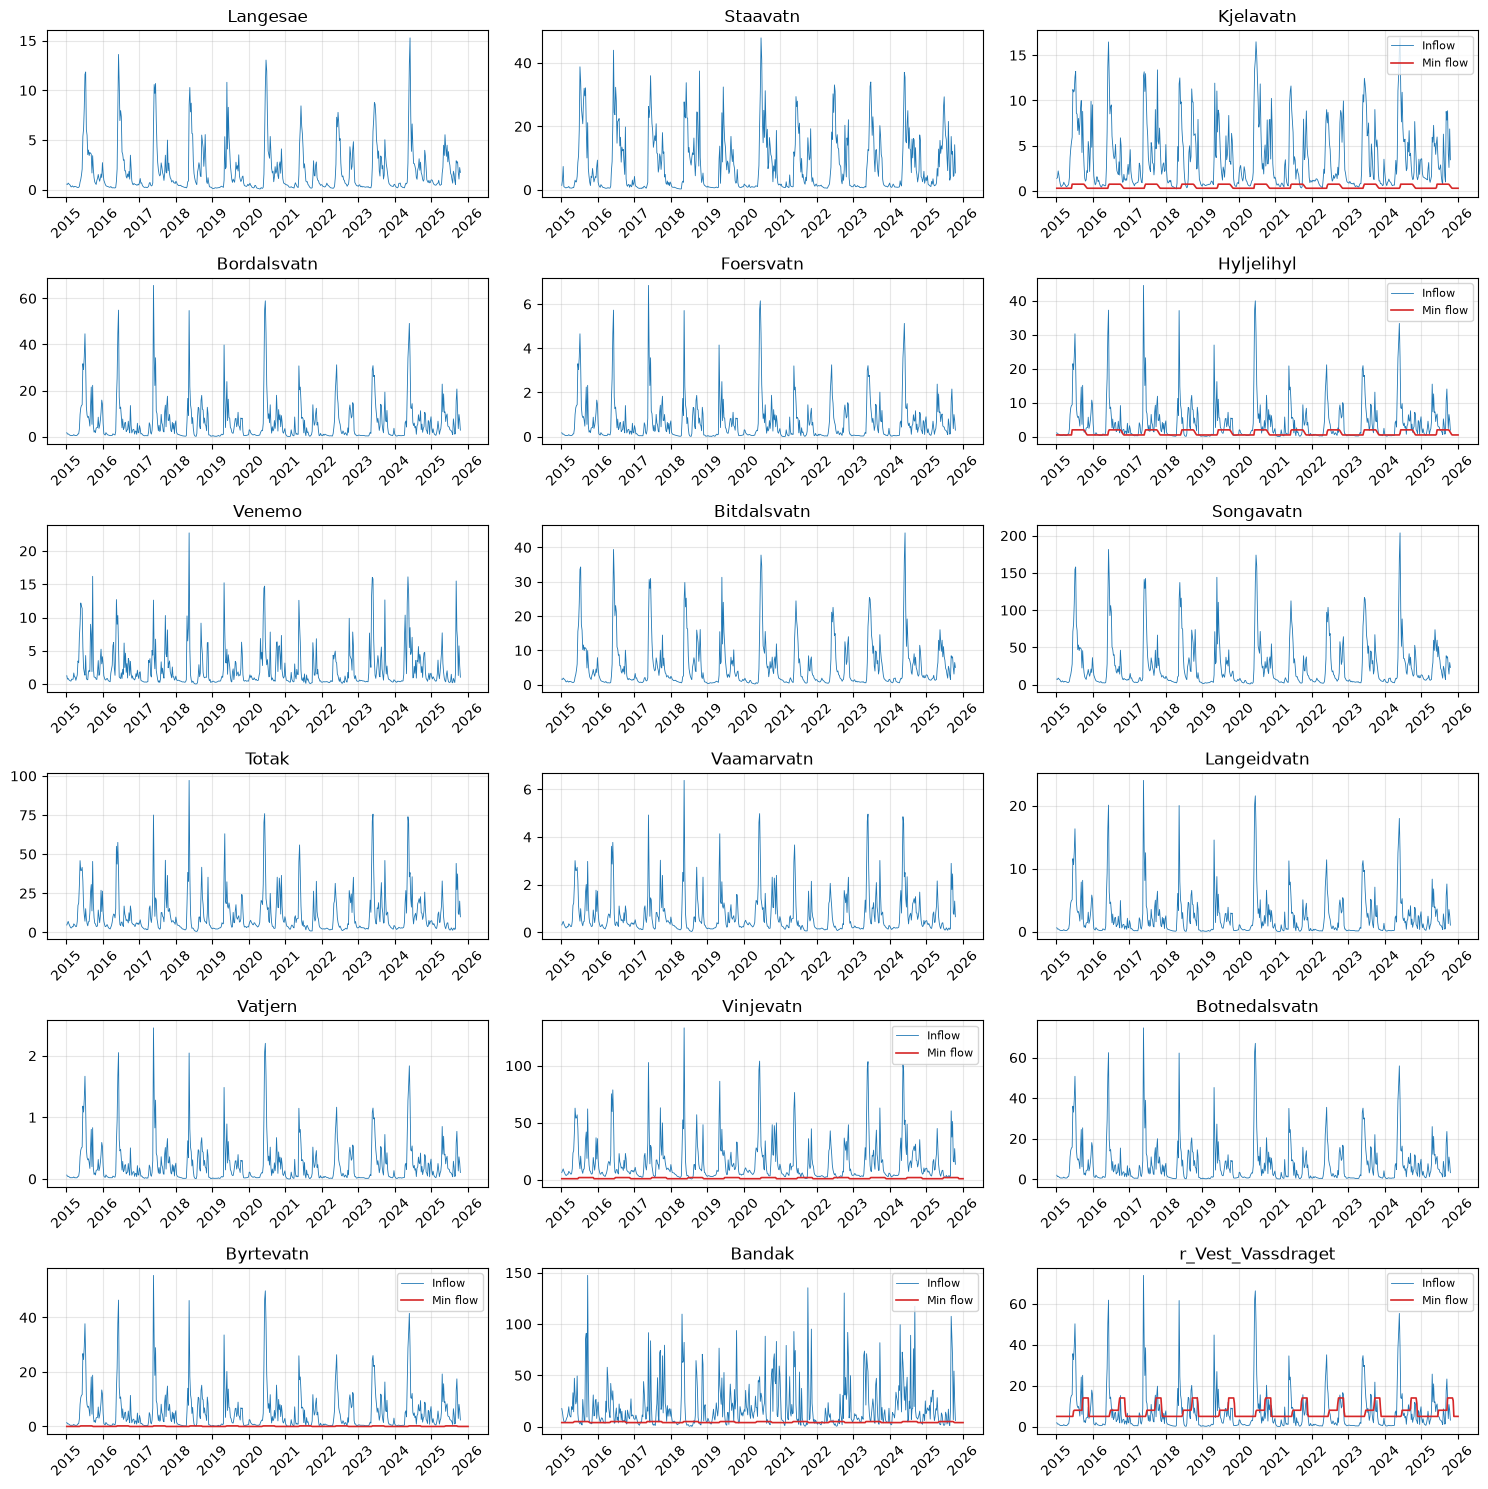

In [4]:
inflow = pd.read_csv("sintef_project/data/kernel/Historical_inflow_1958_2025.csv")
inflow["date"] = pd.to_datetime(inflow["date"])
inflow = inflow[inflow["date"] >= "2015-01-01"]
min_flow = pd.read_csv("sintef_project/data/extended/Constraint_min_flow.csv")
min_flow["date"] = pd.to_datetime(min_flow["date"])
inflow_r = inflow.set_index("date").resample("W").mean()
min_r = min_flow.set_index("date").resample("W").mean()
units = list(inflow_r.columns)
min_map = {c[2:] if c.startswith("b_") else c: c for c in min_r.columns}
ncols = 3
nrows = int(np.ceil(len(units) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 2.5 * nrows), sharex=True)
axes = axes.flatten()
for ax, unit in zip(axes, units):
    ax.plot(inflow_r.index, inflow_r[unit], lw=0.6, label="Inflow")
    if unit in min_map:
        ax.plot(min_r.index, min_r[min_map[unit]], lw=1.2, color="tab:red", label="Min flow")
        ax.legend(loc="upper right", fontsize=8)
    ax.set_title(unit)
    ax.grid(alpha=0.3)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.tick_params(axis="x", labelbottom=True, labelrotation=45)
for ax in axes[len(units):]:
    ax.set_visible(False)
fig.tight_layout()
plt.show()

The volume data was also considered per power plant and visualized as such. These plots also reveal clear patterns, although there are many more variations and deviations than with the inflow data. Most reservoirs seem to again indicate some seasonality with the exception of Vinjevatn and Bandak only showing weak seasonality, which is true to reality as well. (https://sildre.nve.no/station/16.6.0?16.6.0.1000_period=custom&16.6.0.1000_res=0&16.6.0.1000_to=2026-10-30&16.6.0.1000_from=2014-10-30&16.6.0.1000_decimals=3) The storage volume of two reservoirs, Hyljelihyl and Vatjern, also remains unchanged throughout the entire dataset, which seems to be correct (https://vannkart.no/en/stasjon/16.148.0) and implies that no water is stored at these reservoirs, everything flowing in also directly flows back out. Three reservoirs also have minimum volume requirements, which were added to their respective plots. These requirements are also clearly seasonal, and align more closesly with the actuale storage volumes, suggesting a significant effect on the storage volume and as a result the water management of those reservoirs as a whole. These minimum requirements are the result of a ploy to mitigate the impact of the hydropower plants on the local ecology. (https://www.regjeringen.no/no/aktuelt/regjeringen-vedtar-miljoforbedringer-for-tokke-vinje-reguleringen/id2919450/ ) A correlation matrix was again computed and no perfect correlations were present this time, although some strong correlations were present. This can be partly explained by geographical proximity and up-/downstream connectedness but might also imply that these reservoirs are managed using a common shadow price (and as a result turned on/off at mostly the same times).

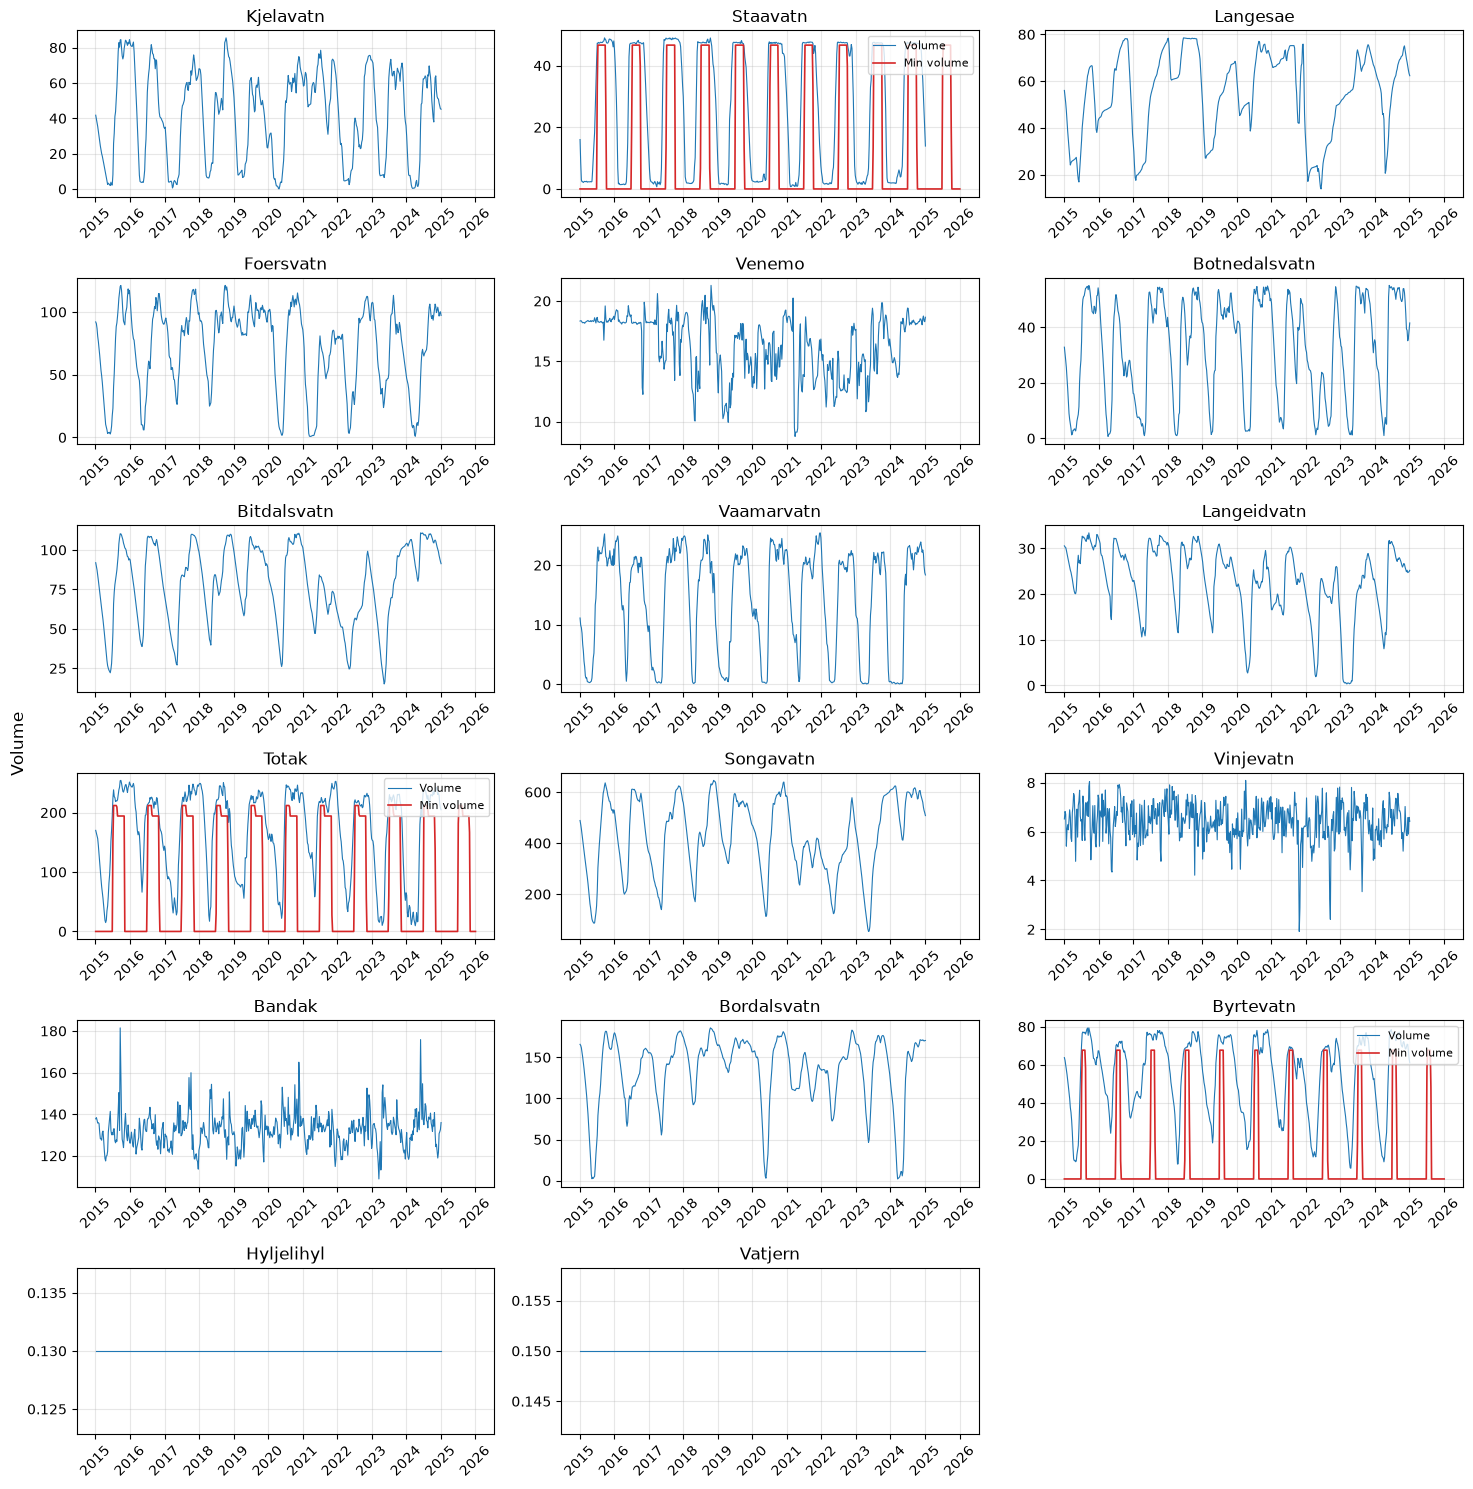

In [5]:
volume = pd.read_csv("sintef_project/data/kernel/Historical_volume_2015_2024.csv")
volume["date"] = pd.to_datetime(volume["date"])
min_vol = pd.read_csv("sintef_project/data/extended/Constraint_min_volume.csv")
min_vol["date"] = pd.to_datetime(min_vol["date"])
volume_r = volume.set_index("date").resample("W").mean()
min_r = min_vol.set_index("date").resample("W").mean()
units = list(volume_r.columns)
ncols = 3
nrows = int(np.ceil(len(units) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 2.5 * nrows), sharex=True)
axes = axes.flatten()
for ax, unit in zip(axes, units):
    ax.plot(volume_r.index, volume_r[unit], lw=0.8, label="Volume")
    if unit in min_r.columns:
        ax.plot(min_r.index, min_r[unit], lw=1.2, color="tab:red", label="Min volume")
        ax.legend(loc="upper right", fontsize=8)
    ax.set_title(unit)
    ax.grid(alpha=0.3)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.tick_params(axis="x", labelbottom=True, labelrotation=45)
for ax in axes[len(units):]:
    ax.set_visible(False)
fig.supylabel("Volume")
fig.tight_layout()
plt.show()

The synthetic water value is important to balance supply and demand of water. If producers set the water value too low, consumption increases, which can lead to empty reservoirs before the dry season is over. This value depends on how long it is possible to store the water, and is calculated using statistics, forecasts, and models to make advanced mathematical calculations on production and consumption. (https://www.nve.no/norwegian-energy-regulatory-authority/the-norwegian-energy-regulatory-authority/water-values-how-do-we-ensure-that-we-utilize-hydropower-in-the-best-possible-way/ ) When plotted, it shows a very similar picture as the day-ahead price: it seems just as volatile and shows almost identical spikes in 2022. The average correlation between the price and water value per unit is 0.88, which makes a lot of sense intuitively as the water value is directly linked to the electricity prices. The water value drops down to just above zero at certain points, which probably indicates an excess of water in those reservoirs. Each reservoir spend about 10% of the time in such a state of excess. The hypothesis of common shadow prices put forward in the previous paragraph also seems to be supported by the fact that several groups of plots have almost identical shapes.

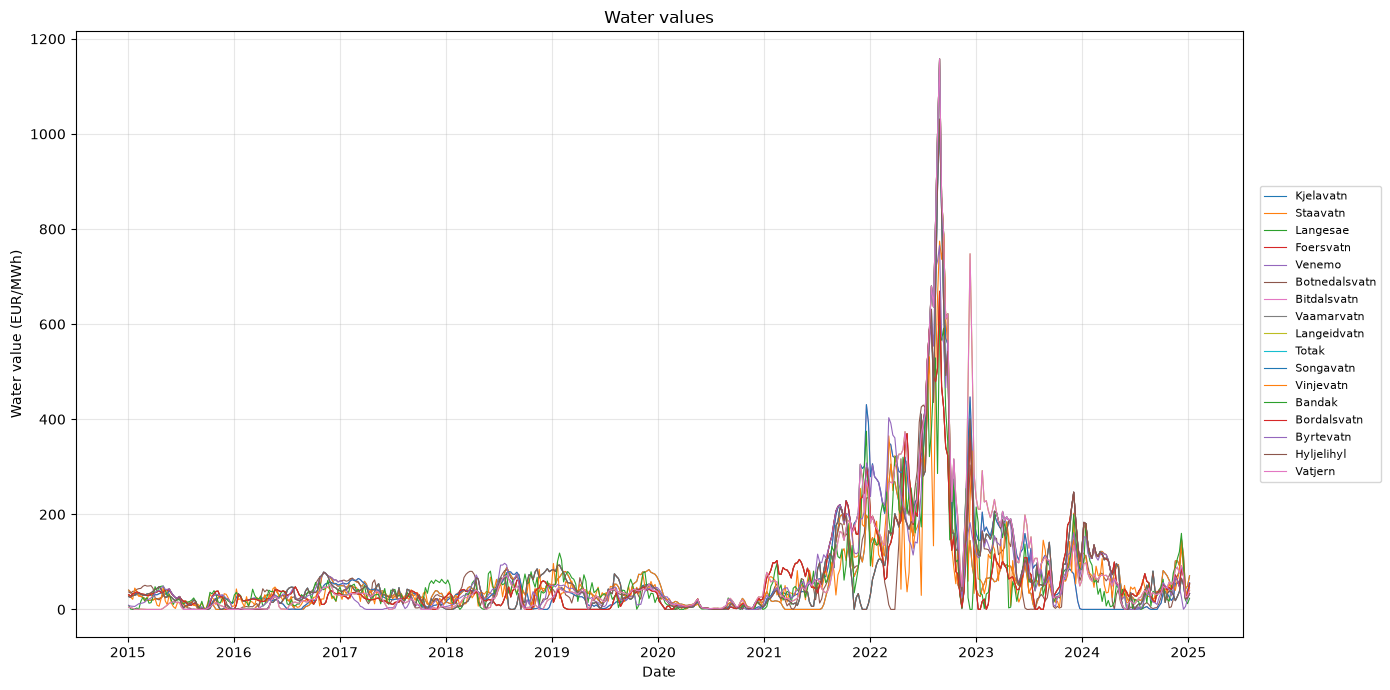

In [6]:
value = pd.read_csv("sintef_project/data/kernel/Synthetic_water_value_2015_2024.csv")
value["date"] = pd.to_datetime(value["date"])
value = value.set_index("date")
value_r = value.resample("W").mean()
fig, ax = plt.subplots(figsize=(14, 7))
for col in value_r.columns:
    ax.plot(value_r.index, value_r[col], lw=0.8, label=col)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Water values")
ax.set_xlabel("Date")
ax.set_ylabel("Water value (EUR/MWh)")
ax.grid(alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8, ncol=1)
fig.tight_layout()
plt.show()

The unit commitment decisions are stored in cases of 168-hour horizons for each of the 14 generating units. For a profit-maximizing producer, generators are expected to be turned on when prices are high. Contrary to this expectation, the median day-ahead price is lower in hours where most generators are committed than in hours where they are off. This holds for 12 of the 14 units, with differences ranging from about -1 to -8 EUR/MWh (largest for Haukeli_G1, Lio_G1, Tokke_G1 and Tokke_G3). The median price when on is remarkably similar across units (about 30 EUR/MWh), while the median price when off varies more. This suggests that commitment is not driven by the spot price alone. Possible explanations are that the decisions come from an optimization with a 168-hour horizon, where the water value, reservoir levels, inflow and minimum flow constraints can outweigh hourly prices. Since water values are partly set by expected future prices, plants may run in moderately priced hours when reservoirs are full or inflow is high, and stay off in high-priced hours if the water is judged more valuable later. Seasonal effects may also play a role, since prices and operation both vary through the year. Overall, price alone is a weak predictor of unit commitment, which motivates informed feature extraction.

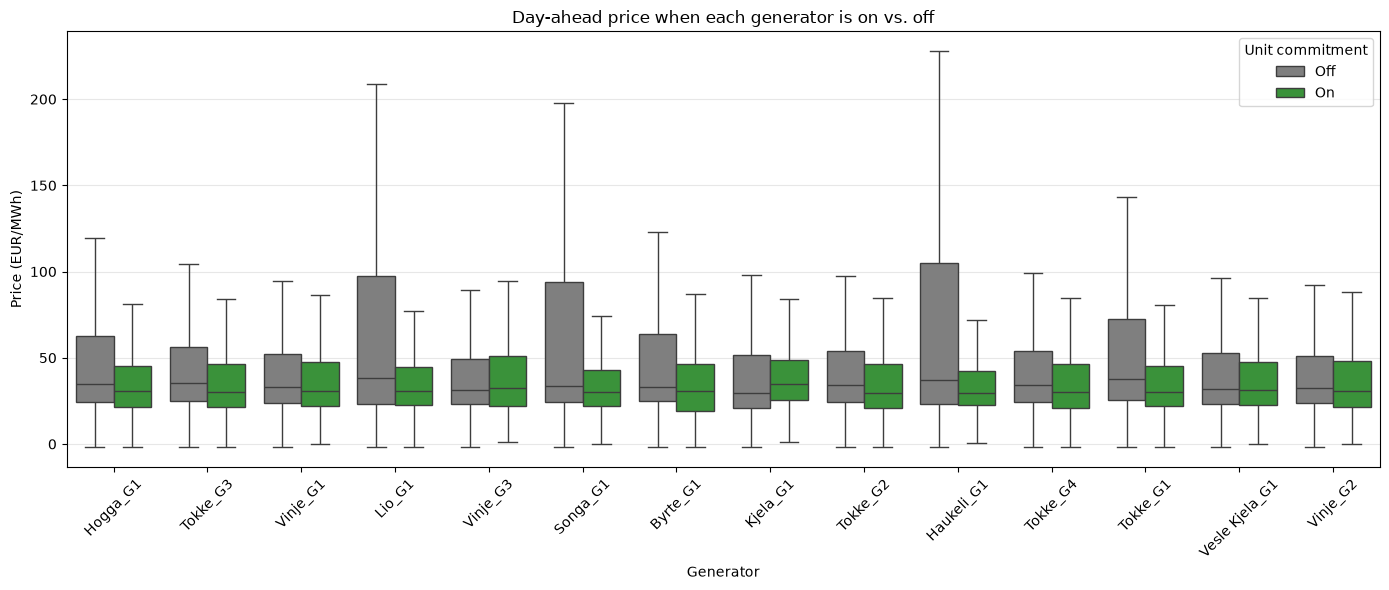

status           Off    On  diff
unit                            
Byrte_G1        33.0  30.8  -2.2
Haukeli_G1      37.3  29.4  -7.9
Hogga_G1        34.8  30.5  -4.3
Kjela_G1        29.4  34.8   5.5
Lio_G1          38.5  30.9  -7.6
Songa_G1        33.6  30.1  -3.5
Tokke_G1        37.9  30.1  -7.8
Tokke_G2        34.4  29.8  -4.6
Tokke_G3        35.4  30.0  -5.5
Tokke_G4        34.3  30.0  -4.2
Vesle Kjela_G1  32.2  31.1  -1.0
Vinje_G1        33.0  30.8  -2.3
Vinje_G2        32.8  30.7  -2.1
Vinje_G3        31.5  32.5   1.0


In [7]:
price = pd.read_csv("sintef_project/data/kernel/Historical_day_ahead_price_2015_2025.csv", parse_dates=["date"], index_col="date")["Day-ahead price (EUR/MWh)"]
price.index = pd.to_datetime(price.index, utc=True).tz_localize(None).floor("h")
price = price[~price.index.duplicated()].rename("price")
uc = pd.read_csv("sintef_project/data/kernel/Unit_commitment_decisions.csv",  parse_dates=["starttime"]).drop(columns=["total_calculation_time"])
long = uc.melt(id_vars=["Run No", "starttime"], var_name="col", value_name="status")
parts = long["col"].str.extract(r"result_committed_(?P<unit>.+)_t(?P<t>\d+)$")
long["unit"] = parts["unit"]
long["t"] = parts["t"].astype(int)
long["time"] = long["starttime"] + pd.to_timedelta(long["t"], unit="h")
long = (long.sort_values("t").drop_duplicates(["unit", "time"], keep="first").drop(columns=["col", "Run No", "starttime"]))
df = long.merge(price, left_on="time", right_index=True, how="inner").dropna(subset=["price"])
df["status"] = df["status"].round().astype(int).map({0: "Off", 1: "On"})
fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=df, x="unit", y="price", hue="status", hue_order=["Off", "On"], palette={"Off": "tab:gray", "On": "tab:green"}, showfliers=False, ax=ax)
ax.set_title("Day-ahead price when each generator is on vs. off")
ax.set_xlabel("Generator")
ax.set_ylabel("Price (EUR/MWh)")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Unit commitment")
fig.tight_layout()
plt.show()
print(df.groupby(["unit", "status"])["price"].median().unstack().assign(diff=lambda d: d["On"] - d["Off"]).round(1))

The topology file describes the physical structure of the watercourse as a directed graph of 17 reservoirs, 9 power plants with 14 generating units (1003 MW installed in total), 5 tunnels and 37 river segments (bypass, spill and regulated flow). The figure below shows the resulting network, with elevation on the vertical axis and the flow direction running from upstream (left) to downstream (right). It shows that the system is a strongly coupled cascade rather than a set of independent plants. The reservoirs span roughly 1000 m of elevation, from Langesae (HRL 1090 m) down to Bandak (73 m), and almost all water ends up in Bandak, either through the Tokke plant or through the river Vest-Vassdraget. The longest chain starts at Songavatn and passes through Songa, Totak, Vaamarvatn, Vinje, Vinjevatn, Tokke and Bandak before reaching Hogga. This means the discharge of an upstream plant becomes the inflow of the reservoir feeding the next plant, so that the commitment of one unit changes the water available to the units below it. Vinjevatn acts as a hub, receiving the discharge of Vinje and Haukeli and several river flows, and it feeds Tokke, the largest plant (4 x 107.5 MW). Reservoir sizes also differ strongly: Songavatn (640) is by far the largest, followed by Totak, Bordalsvatn and Bandak, while Hyljelihyl (0.26) and Vatjern (0.3) have almost no storage capacity. This agrees with the constant volumes found for these two reservoirs above, and it explains why they behave like pass-through points. The topology also supports the earlier observations that some reservoirs have perfectly correlated inflows and that several water values look alike, since reservoirs directly above or below each other share inflow patterns and probably the same marginal value of water. For feature engineering, this suggests that features of the upstream and downstream neighbours of a unit (such as their volumes, inflows or water values) may be informative in addition to features of the unit's own reservoir.

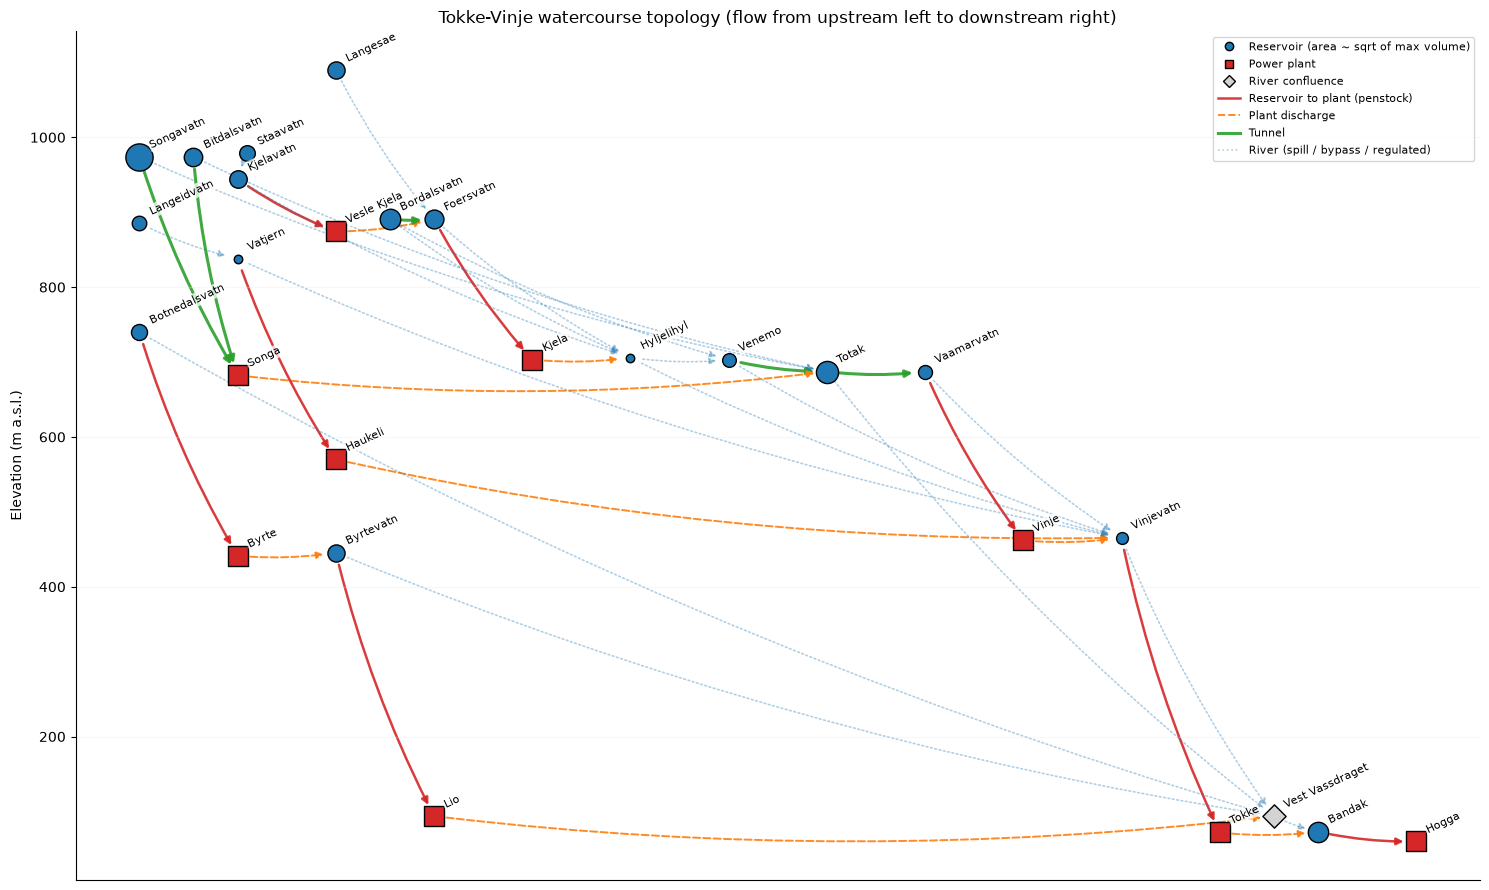

17 reservoirs, 9 plants, 14 generators, 5 tunnels, 37 river segments; installed capacity 1003 MW


In [17]:
import yaml
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

with open("sintef_project/data/extended/Tokke_Vinje_topology.yaml") as f:   # adjust path if needed
    topo = yaml.safe_load(f)
model, conns = topo["model"], topo["connections"]
res, plants, tunnels, rivers, gens = (model[k] for k in ("reservoir", "plant", "tunnel", "river", "generator"))

# Full graph: reservoirs, rivers, tunnels and plants are nodes (generators are attached to their plant)
raw = nx.DiGraph()
raw.add_edges_from((c["from"], c["to"]) for c in conns if "generator" not in (c["from_type"], c["to_type"]))

# Collapse pass-through rivers/tunnels into edges; the confluence river r_Vest_Vassdraget (several inputs) stays a node
keep = lambda n: n in res or n in plants or n == "r_Vest_Vassdraget"
G = nx.DiGraph()
G.add_nodes_from(n for n in raw if keep(n))
for u, v in raw.edges:
    if keep(u) and keep(v):
        G.add_edge(u, v, kind="direct")
for n in raw:
    if not keep(n):
        for u in raw.predecessors(n):
            for v in raw.successors(n):
                if not (G.has_edge(u, v) and G[u][v]["kind"] == "tunnel"):
                    G.add_edge(u, v, kind="tunnel" if n in tunnels else "river")

# Node elevation (m): reservoir HRL, plant outlet line, confluence river elevation
elev = {n: res[n]["hrl"] for n in res}
elev.update({p: plants[p]["outlet_line"] for p in plants})
elev["r_Vest_Vassdraget"] = rivers["r_Vest_Vassdraget"]["upstream_elevation"]

def category(u, v, d):
    if d["kind"] == "tunnel":
        return "Tunnel"
    if v in plants:
        return "Reservoir to plant (penstock)"
    if u in plants:
        return "Plant discharge"
    return "River (spill / bypass / regulated)"

style = {"Reservoir to plant (penstock)": dict(color="tab:red", ls="-", lw=1.8, alpha=0.9),
         "Plant discharge": dict(color="tab:orange", ls="--", lw=1.4, alpha=0.9),
         "Tunnel": dict(color="tab:green", ls="-", lw=2.2, alpha=0.9),
         "River (spill / bypass / regulated)": dict(color="tab:blue", ls=":", lw=1.2, alpha=0.35)}

# Layout: x = depth in the flow network (upstream -> downstream), y = elevation
depth = {n: 0 for n in G}
for n in nx.topological_sort(G):
    for p in G.predecessors(n):
        depth[n] = max(depth[n], depth[p] + 1)
for n in reversed(list(nx.topological_sort(G))):          # pull pure sources towards their targets
    if G.in_degree(n) == 0 and G.out_degree(n) > 0:
        depth[n] = min(depth[s] for s in G.successors(n)) - 1
pos = {}
for L in sorted(set(depth.values())):
    prev, x_off = None, 0
    for n in sorted((n for n in G if depth[n] == L), key=lambda n: elev[n]):
        x_off = x_off + 0.55 if prev is not None and elev[n] - prev < 60 else 0   # separate near-equal elevations
        pos[n] = (L - min(depth.values()) + x_off, elev[n])
        prev = elev[n]

fig, ax = plt.subplots(figsize=(15, 9))
for u, v, d in G.edges(data=True):
    st = style[category(u, v, d)]
    ax.annotate("", xy=pos[v], xytext=pos[u], zorder=1,
                arrowprops=dict(arrowstyle="-|>", shrinkA=9, shrinkB=9, connectionstyle="arc3,rad=0.06",
                                color=st["color"], ls=st["ls"], lw=st["lw"], alpha=st["alpha"]))
for n, (x, y) in pos.items():
    if n in res:
        ax.scatter(x, y, s=30 + 14 * np.sqrt(res[n]["max_vol"]), c="tab:blue", edgecolor="k", zorder=3)
    elif n in plants:
        ax.scatter(x, y, s=220, marker="s", c="tab:red", edgecolor="k", zorder=3)
    else:
        ax.scatter(x, y, s=140, marker="D", c="lightgray", edgecolor="k", zorder=3)
    ax.annotate(n.replace("r_", "").replace("_", " "), (x, y), xytext=(6, 6), textcoords="offset points",
                fontsize=8, rotation=25, zorder=4, bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.75))

handles = [Line2D([], [], marker="o", ls="", mfc="tab:blue", mec="k", label="Reservoir (area ~ sqrt of max volume)"),
           Line2D([], [], marker="s", ls="", mfc="tab:red", mec="k", label="Power plant"),
           Line2D([], [], marker="D", ls="", mfc="lightgray", mec="k", label="River confluence")]
handles += [Line2D([], [], color=s["color"], ls=s["ls"], lw=s["lw"], alpha=s["alpha"], label=k) for k, s in style.items()]
ax.legend(handles=handles, loc="upper right", fontsize=8)
ax.set_xticks([]); ax.set_ylabel("Elevation (m a.s.l.)"); ax.grid(axis="y", alpha=0.3)
ax.set_title("Tokke-Vinje watercourse topology (flow from upstream left to downstream right)")
fig.tight_layout()
plt.show()

print(f"{len(res)} reservoirs, {len(plants)} plants, {len(gens)} generators, {len(tunnels)} tunnels, "
      f"{sum(n.startswith(('b_', 's_', 'r_')) for n in rivers)} river segments; installed capacity {sum(g['p_nom'] for g in gens.values()):.0f} MW")

## Feature Engineering
The EDA showed that the raw variables relate to UC decisions in complex and often indirect ways, meaning the information needed to explain the commitment decisions is not fully captured by the raw columns and needs to be made explicit through feature engineering. Both feature extraction to create new variables from the existing data, for instance by combining, transforming or aggregating columns so that the relationships relevant to the problem become easier for a model to exploit, and feature selection, reducing the resulting feature set to the variables that carry useful information, which limits redundancy, lowers the risk of overfitting and keeps the models interpretable, are used.


#### Baseline model
To start, simple xgboost models were trained on the features exactly as they appear in the data: the day-ahead price, inflow, reservoir volume, water value, minimum volume and minimum flow, aligned to a common time resolution, with the unit commitment status as the target. This model used logistic regression and a shallow decision tree because those are fast, easy to interpret and make few assumptions, so any improvement can be attributed to the features rather than to model complexity. The performance was measured with accuracy and ROC-AUC. This baseline serves two purposes. It gives a reference score that every later feature set must beat to justify its added complexity, and it shows how much of the commitment behaviour is already explained by the raw data.

#### Candidate features from domain logic
Rather than generating features blindly, knowledge of the operation of hydropower producers was used to come up with candidates that reflect the underlying decision problem. A reservoir-based producer does not simply run when the price is high. It compares the current price with the value of storing the water for later, and it is restricted by physical and regulatory limits. This led to the following groups of candidates:

- Economic signals. The difference or ratio between the day-ahead price and the water value is the most direct expression of the producer’s decision     rule: produce when the price exceeds the value of stored water. We also considered the price relative to its recent average, and its rank within the   day or week, to capture whether an hour is cheap or expensive in context.
- Temporal patterns. Hour of day, day of week and month capture the daily load pattern and the seasonal cycle. Lagged and rolling-window versions of     the price (e.g. previous 24 hours, 7-day mean) capture short-term market dynamics.
- Reservoir state and constraints. The headroom above the minimum volume (volume − min_volume), the volume as a fraction of its historical range, and    the change in volume over recent days describe how much flexibility a unit has. Likewise, inflow minus minimum flow indicates whether the flow         constraint is binding. Cumulative or lagged inflow reflects the delayed response of reservoirs to snowmelt and rain.
- System and plant interactions. Generators in the same cascade or power station tend to be operated together, and due to the connectedness of the       system, reservoirs and plants that are upstream/downstream from each other can significantly influence outcome decisions.

Throughout the candidate generation and filtering, relative features (differences, ratios, ranks and normalised values) were favoured over the raw absolute values for several reasons: They are robust to changes over time, as price levels shifted considerably over the period 2015-2026, so a threshold learned from absolute prices in the training years may not hold in the test years. They are comparable across units, which is crucial because reservoirs differ greatly in size, and plants differ in capacity, so a volume of a given size means very different things for different units. And they match the decision logic: A producer does not compare the price to a fixed number but to the value of the stored water

#### Candidate filtering
This candidate set is large and contains many overlapping features, so before running expensive cross-validated model comparisons a quick univariate filter was applied. It was computed separately for each unit, since the same feature can matter for one generator and not for another. The purpose of the filter is to prune clearly useless features cheaply. It is not meant to produce the final feature set, because it scores each feature in isolation and therefore misses interactions between features. Each feature was scored against the on/off target with up to three measures:

- Spearman correlation. This rank-based correlation is robust to outliers (price spikes are common in this data) and detects any monotonic               relationship, not only linear ones.
- Single-feature AUC, scored as |AUC − 0.5|. The ROC-AUC was computed when using the feature alone as a classifier score, and its distance from 0.5 (random guessing) was measured. Taking the absolute value makes the score direction-agnostic, so features that predict “off” as strongly as “on” are not penalised. AUC is considered the most important score as it is also the metric on which the final models are evaluated.
- Mutual information. Mutual information captures non-monotonic relationships that correlation misses. Hour of day is a typical example: a unit may be   on during the day and in the evening but off at night, so the Spearman correlation is close to zero even though the feature is highly informative.

To check that a feature’s effect is reliable rather than the result of one unusual period, a sign consistency score was also computed (the share of years in which the feature’s effect on the target has the same sign). These scores were then interpreted using three principles rather than a fixed cut-off: A feature with a small effect that has the same sign in every year is more trustworthy than a strong effect that appears in one year only and reverses in others. Only features with near-zero strength in every unit and no domain reason to matter were removed. The filter was deliberately lenient, because a feature can score low on its own and still help through interactions. Categorical or cyclical features were not judged by correlation, as hour of day and month look weak under Spearman because their relationship with the target is not monotonic (and they did also score poorly on AUC as expected), but rather by mutual information.

#### Final feature selection
The final feature set was chosen differently: feature groups were repeatedly added, removed or reformulated, to train increasingly complex models on each version, while keeping changes that improved validation performance. This was trial and error, but guided by the domain logic from the second step. The result is a single feature set, called variant L, which feeds both final models. They differ in the learners built on top of it. The final features fall into three groups, all computed per plant.

Relative market and state features. Following the argument for relative over absolute features, almost all price features are expressed relative to a reference level (although absolute values such as reservoir volume and inflow were kept as well, because relative features discard level information):

- Price shape: the log of the price divided by the weekly mean, the same quantity one hour earlier and later, the rank of the price within the day and   within the week, and standardised deviations from the daily and weekly mean.
- Price versus water value: the log of the price divided by the water value at the start and end of the week, for each reservoir the plant uses. This    is the direct implementation of the producer’s decision rule.
- Reservoir state and constraints: the fill level, the volume above the minimum volume, the downstream shortfall and the head, rather than raw volumes   alone.
- Spill pressure: cumulative inflow divided by capacity, and the volume plus cumulative inflow minus maximum volume, divided by capacity. This           captures how close a reservoir is to spilling, which forces the plant to run regardless of price.
- Calendar and season: hour of week, hour of day, day of week and day of year. The cyclical features were kept because they carry information that       correlation filters underrate.

Before any model was trained, we checked how informative three scores are when used alone against the unit commitment (Table 1). The price rank within the week, which only says which hours are the cheapest or most expensive, has a micro AUC of 0.589. The log of the price divided by the water value reaches 0.872. Comparing the price with the value of the stored water therefore carries far more information about the commitment than the price pattern alone.

**Table 1.** Micro AUC of single scores used alone against the unit commitment (all cases, 2015-2022).

| Score used alone | Micro AUC |
|---|---|
| Price rank within the week | 0.589 |
| log(price / water value) | 0.872 |
| Optimizer surrogate (estimated running units) | 0.777 |

Optimizer-based features. The most distinctive step was to turn small optimization problems into features, so that the learners receive an approximation of the scheduling decision instead of having to discover it from raw columns. The reasoning is that price features tell a model which hours are the best, but not how many hours a plant will run in a week, which depends on the available water, the turbine capacity and the water value. An error analysis of the model without surrogates showed that most of the remaining error was at this weekly level. None of these features uses the labels: they are built only from inputs known at the start of the week, and the labels serve only to evaluate them.

- Optimizer surrogate: a fast approximation of the scheduling decision for one plant. The weekly water budget is estimated from the hours in which the   price exceeds the water value, limited by the water available and the turbine capacity, and then poured into the highest-priced hours until it is      used up. The result is an hourly dispatch profile, computed for four budgets (the minimum to avoid spill, the water value at the start of the week,    the water value at the end, and the maximum usable). For a typical week, the surrogate therefore switches units on in the hours where the price is     well above the water value and leaves them off in the cheap hours, which is the pattern a producer following the decision rule would show. The         resulting budget follows the real share of running hours per week, which the price rank cannot do because its weekly mean is the same in every week.   Across non-overlapping weeks, the correlation between the budget and the real share of ON hours is high for Vesle Kjela (r = 0.97), Songa (0.95) and   Byrte (0.99), and still good for Kjela (0.91) and Hogga (0.88). It is weaker for Lio (0.70), Haukeli (0.62), Vinje (0.50) and Tokke (0.44), where      the water coming from upstream is harder to approximate.
- Viterbi on/off margins: a two-state forward-backward pass computes, for each unit and hour, the best weekly value with the unit on minus the best      value with it off, including start and stop costs. Commitment decisions are persistent and starts cost money, so a unit does not switch on for a       single cheap hour. The margins encode this without using the target. They are computed for three price definitions, namely price minus water value     and two versions scaled by the unit’s marginal power ratio.
- Cascade linear program (LP): the surrogate looks at one plant at a time and only approximates the water coming from upstream, and its budget often     saturates at 0 or 1. One weekly LP over all reservoirs, rivers, tunnels and generators removes this limit and gives the relative flow and the          reduced cost divided by the water value for each unit. It has no on/off variables and no start/stop costs, so these features are soft signals rather   than exact answers. On the same weeks, the LP reduced cost alone reaches a micro AUC of 0.900, against 0.774 for the surrogate. The improvement is     largest where the surrogate was weakest: for Tokke, the correlation of the weekly LP flow with the real share of running hours is 0.86, against 0.44   for the surrogate budget.

Cascade features. Since plants share water, a plant’s decisions depend on those upstream of it. For the tree branches, the predicted commitment of upstream plants (mean probability, lagged by 1 and 3 hours, and weekly mean) and the expected upstream release become features of the downstream plant. Predictions are generated out-of-fold, so no information leaks from the targets into the training features. The TCN does not need these features because it sees all plants at once.

Table 2 shows the main steps of the trial-and-error process. Not every step produced a measurable gain. Differences between runs of the same model are about 0.0015 micro AUC, so the last two steps (per-unit physics and the LP) are within the run-to-run variation on the test set. The clearest gains come from the surrogate and from the constraint-corrected surrogate. Only the step from C to S isolates one change; the later steps also changed other things, such as the use of unscaled prices and water values and a topology fix for Haukeli, so their gains cannot be attributed to a single feature group. The gains are also not uniform across units: the surrogate improved Tokke (+0.038 on the test set), Lio (+0.034) and Hogga (+0.020), but made Songa worse (−0.026).

**Table 2.** Micro AUC of the feature variants, trained on the first 80% of the cases and tested after a 7-day gap.

| Variant | Content | OOF | Test |
|---|---|---|---|
| C | Base: price, inflow, volumes, water values, stacking | 0.9612 | 0.9438 |
| S | C + surrogate dispatch | 0.9716 | 0.9570 |
| K | S + surrogate corrected by min flow / min volume, constraint features | 0.9754 | 0.9715 |
| N | K + unscaled prices and water values, Haukeli topology fix | 0.9780 | 0.9806 |
| P | N + per-unit physics and start/stop costs | 0.9788 | 0.9823 |
| L | P + LP of the cascade | 0.9811 | 0.9825 |

Two things stand out. First, the engineered features did what the exploratory analysis suggested. The raw price was a weak predictor of commitment, but the combination of price, water value and reservoir state, summarised by the surrogate and Viterbi features, supports micro AUCs of about 0.983 for the tree branches on the local test set. Second, the benefit differs by unit. Units in the lower cascade and the large Tokke and Vinje stations score around 0.98 to 0.99, while Haukeli (about 0.92) and Lio (about 0.94) remain hardest. Both depend on reservoirs whose water values come from neighbouring reservoirs in our mapping, so the water-value features are probably the least precise for them. This is a plausible explanation rather than something we tested directly, although the topology fix and the LP both mainly improved Haukeli (the LP raised its test AUC from 0.898 to 0.923).

## Model Selection

At the beginning multiple models were chosen for the tree based models multiple different models light lightGBM, XGBoost and Random Forest were explored. Similarly different Neural networks were explored. Thereby it was determined that tree based models were able to achieve rather good baseline results just based on the initial unadjusted parameters especially after introducing the spread for each resercoir calculated as:

$$
\text{Spread} = \text{Day-ahead Price} - \text{Water Value}
$$

Therefore the first model versions focused on improving a tree based model, which was later expanded by a neural network.

To evaluate the models the dataset from January 1st 2015 to December 31st 2022 was seperated into a training and a test dataset (80/20). Because we deal with time series it was important to split them chronological. So the resulting training data reaches from January 1st 2015 till May 25th 2021. The test data reaches from June 2nd 2021 to December 31st 2022. The gap between those two was included to avoid testing on data that overlaps.

The final models for the kaggle submissions were then trained on the data from until the 31st December 2022. With the final two years recieving an higher weight (2.0) to account for the differing market conditions about them closer to the current ones.

#### Data Formatting for Tree-Based Models vs. Neural Networks
To predict the hourly unit commitment status for all 14 hydropower generators over a 168-hour weekly horizon, we structure the input data differently for the two model types:

**Tree-Based Models:** For the tree-based models, we use a long tabular format for each power plant where every row represents a single operational hour for one generator. If a plant has multiple generators, their rows are stacked on top of each other into one dataset, using an indicator column to distinguish between the individual units.

**Neural Network (TCN):** For the neural network, we keep the 168-hour weekly sequence intact and combine the features of all power plants into a single 3D tensor (cases, features, 168 hours). The features are standardized, and the network predicts the entire 168-hour schedule for all 14 generators at once.


#### Model v2

We started by shrinking our massive dataset down to 58 key components using PCA, and then trained a basic Random Forest model on this simplified data.

#### Model v3

We added several new physical features, like how full the reservoirs were and the water pressure. We combined these directly with the shrunken hourly data to make the Random Forest smarter.

#### Model v4-A

We switched to a more powerful algorithm called XGBoost and trained a completely separate model for every single power generator.

#### Model v4-B

We upgraded the XGBoost models to share information. Upstream plants started passing their predictions down to the downstream plants (a technique we called "topological stacking").

#### Model v4-C

Instead of training a model for every single generator, we grouped them and trained one unified model per power plant. This made the learning process much more stable.

#### Model v4-tuned

We kept the v4-C setup but carefully adjusted the internal math settings (hyperparameters) of each power plant's model to squeeze out the best possible score.

#### Model v8

We smoothed out our predictions by averaging overlapping 7-day periods to reduce random noise, and we mathematically tweaked the probabilities so they were aligned across all the different units.

#### Model v9

We built an "Optimizer Surrogate" (SURR) that simulates how a real dispatcher would allocate a weekly water budget to the most profitable hours. We also experimented with looking at similar historical weeks to guess the current one.

#### Model v10

We realized the simulator (SURR) worked great for some plants but not others. In this version, we selectively applied it only to the specific power plants where it actually improved the score.

#### Model v11

We injected strict environmental rules into the model, making sure it understood mandatory minimum water flows for certain rivers and minimum summer volumes for specific lakes.

#### Model v12

To handle extreme market price spikes, we converted prices and water values into relative ratios and percentages so the model wouldn't get confused by record-high numbers it had never seen before.

#### Model v14

We made the physics much more realistic by calculating actual water pressure losses and dynamically figuring out if the start/stop costs made it financially worth turning a unit on.

#### Model v15

We introduced Deep Learning (a Temporal Convolutional Network or TCN) that can look at the whole week and all 14 units at the exact same time, and then averaged its predictions with XGBoost.

#### Model v17

We added a full mathematical simulation (Linear Programming) of the entire river cascade to calculate the absolute perfect water flow, and fed those perfect calculations into XGBoost as a hint.

#### Model v18

We combined our most advanced XGBoost setup (with physics, start costs, and the river simulations) with our Deep Learning model to get the best of both worlds.

#### Model v19 (AutoGluon)

We swapped out XGBoost for an automated tool called AutoGluon, which trains and combines several different algorithms (like LightGBM and CatBoost) all at the same time.

#### Model v19 (TCN)

We upgraded our Deep Learning model, making it wider and letting it train for longer so it could catch deeper, more complex patterns in the weekly data.

#### Model v19 (Blend)

Our final step was to mathematically average the predictions from the AutoGluon ensemble and the upgraded Deep Learning model to create our ultimate, most accurate prediction.




<Axes: title={'center': 'ROC-AUC Scores'}>

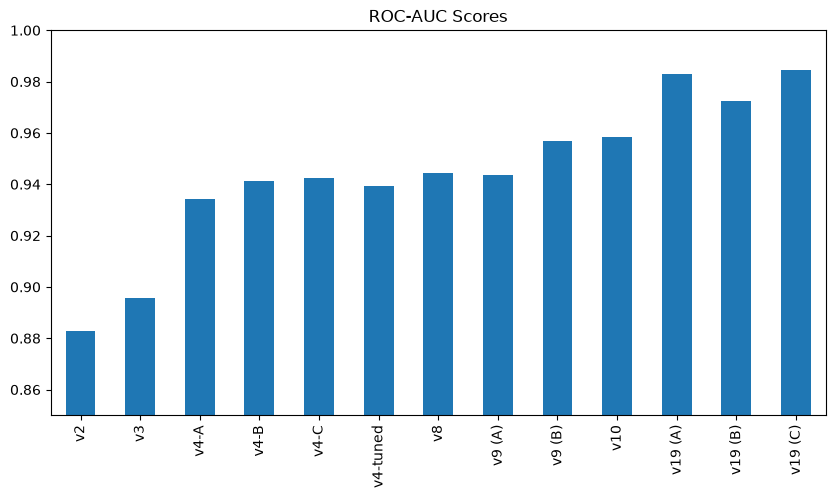

In [15]:
scores = {
    "v2": 0.8830, "v3": 0.8957, "v4-A": 0.9344, "v4-B": 0.9412, "v4-C": 0.9423, 
    "v4-tuned": 0.9393, "v8": 0.9445, "v9 (A)": 0.9438, "v9 (B)": 0.9570, 
    "v10": 0.9585, "v19 (A)": 0.9830, "v19 (B)": 0.9723, "v19 (C)": 0.9847
}

pd.Series(scores).plot(kind='bar', ylim=(0.85, 1.0), title='ROC-AUC Scores', figsize=(10, 5))

## Final Models

The two final models that were submitted are Version 18 and Version 20. They are structured similarly to each other and employ the following architectures:

**Version 18:** Uses XGBoost and a Temporal Convolutional Network (TCN) and blends the predictions.

**Version 20:** Uses AutoGluon—which trains multiple tree-based models—and a Temporal Convolutional Network, and blends the predictions.

First, the selected features are explained, and afterwards, the selected Machine Learning models are presented.

### Preprocessing

During model development, multiple characteristics were identified that significantly increased the models' performance:

- **Temporal Features:** The hour of the prediction horizon (0 to 167), the hour of the day (0 to 23), the day of the week (0 to 6), and the day of the year to account for the identification of temporal patterns.
- **Day-Ahead Electricity Price Features:** Relative logarithmic price levels compared to the weekly mean (including 1-hour forward and backward lags), normalized hourly price ranks across both the entire 168-hour week and each 24-hour day, price z-scores relative to the daily and weekly means, and the logarithmic difference between hourly prices and the initial and final water values of the upstream and downstream reservoirs.
- **Inflow and Overflow Risk:** Tracks the hourly and weekly average natural water inflows from upstream reservoirs. To evaluate the risk of reservoirs overflowing, it calculates a "spill pressure" metric, representing the excess water (initial volume plus cumulative inflows minus maximum storage capacity) normalized by the plant's maximum discharge capacity to indicate the necessity for the plant to run.
- **Static Reservoir and Hydraulic Features:** Initial reservoir volumes (both absolute and as a fraction of maximum capacity), logarithmic initial and final water values, upstream water elevation (hydraulic head), net hydraulic head accounting for downstream elevation and the turbine outlet line, the logarithmic water value difference between upstream and downstream reservoirs, and the total normalized water volume available from secondary feeder reservoirs.
- **Environmental and Physical Constraints:** Active minimum flow and minimum volume constraints for the relevant reservoirs and rivers, available upstream volume above the minimum requirement, downstream volume deficit relative to minimum volume requirements, and specific flow deficit metrics for the Lio plant.


### Feature Engineering in the Model

We found that by processing the data through three domain-specific sub-models, we could generate new features that significantly boosted the performance of the tree-based models, regardless of the specific algorithm used (XGBoost, LightGBM, or ExtraTrees). These three models are explained in the following sections.


#### Surrogate Model

Our first model to employ the surrogate model was Model v9, where we raised the ROC-AUC from 0.944 to 0.957. The purpose of the surrogate model is to incorporate the physical constraints of the available water into the pipeline, determining how much water is available for usage by each generator by calculating the minimum and maximum bounds and identifying when best to use it. 

The surrogate model approximates hydropower dispatch over a 168-hour horizon without solving the full unit commitment problem. First, the maximum turbine discharge capacity $c_p$ (Mm³/h) is estimated from the nominal power $P_{p_\mathrm{nom}}$ (MW) given in the topology, hydraulic head $H_p$ (m), and an assumed efficiency of $\eta=0.88$:

$$
H_p = \max\left(h_{\mathrm{up}}-\max(h_{\mathrm{down}},h_{\mathrm{outlet}}),5\right)
$$

$$c_p = \frac{P_{p_\mathrm{nom}}}{2.725\cdot\eta\cdot H_p}$$

Here, $h_{\mathrm{up}}$ and $h_{\mathrm{down}}$ denote the upstream and downstream water elevations, while $h_{\mathrm{outlet}}$ represents the turbine outlet elevation (all in metres). The factor 2.725 accounts for the unit transformation to Mm³/h.

The available water volume $V_{\mathrm{available}}$ (Mm³) is calculated from the initial reservoir storage $V_0$ (Mm³), natural inflows $Q_{\mathrm{in},t}$ (m³/s), and the released volume upstream $V_{\mathrm{upstream}}$ (Mm³):

$$V_{\mathrm{available}}=V_0+0.0036\sum_{t=1}^{168}Q_{\mathrm{in},t}+V_{\mathrm{upstream}}$$

The factor 0.0036 converts the inflows from m³/s to Mm³. The weekly water budget $W$ (Mm³) is therefore limited by:

$$W_{\max}=\operatorname{clip}(V_{\mathrm{available}}-V_{\mathrm{required}},0,168c_p)$$

With $168c_p$ representing the volume used if the turbine were to run at full capacity for the entire week.

$$W_{\min}=\min\left(\max(V_{\mathrm{available}}-V_{\mathrm{storage,max}},0),W_{\max}\right)$$

Here, $V_{\mathrm{required}}$ represents the minimum reservoir storage requirement, and $V_{\mathrm{storage,max}}$ the maximum reservoir capacity, both in Mm³. Thus, $W_{\min}$ represents the minimum release required to avoid exceeding storage capacity, while $W_{\max}$ represents the maximum usable water volume.

The economically desirable water consumption is estimated by identifying hours in which the day-ahead electricity price $P_t$ exceeds the reservoir water value $\lambda$, both expressed in monetary units per MWh:

$$W_{\mathrm{econ}}=\operatorname{clip}\left(c_p\sum_{t=1}^{168}\mathbb{1}(P_t>\lambda),W_{\min},W_{\max}\right)$$

Finally, the available water budget $W$ is preferentially allocated to the hours with the highest electricity prices:

$$\hat{u}_{p,t}(W)=n_p\cdot\operatorname{clip}\left(\frac{W}{c_p}-r_t,0,1\right)$$

Here, $\hat{u}_{p,t}$ is the plant-level dispatch indicator, $n_p$ denotes the number of generating units in plant $p$, and $r_t$ represents the zero-based descending electricity-price rank of hour $t$, ranging from 0 (highest price) to 167 (lowest price).

Four dispatch profiles are generated using the minimum, maximum, and two economically determined water budgets. The profile based on the final water value, denoted by $S_{2,p,t}$, is additionally adjusted for individual generating units using $S_{p,j,t}=S_{2,p,t}-j$, where $j$ is the zero-based unit index within plant $p$.

#### Start/Stop Cost Evaluation (Viterbi)

When evaluating earlier versions of our models, we observed that the predicted commitment decisions exhibited substantially more frequent switching between ON and OFF states than the actual test data. In particular, the true commitment decisions showed that generating units often remained operational for extended periods, sometimes spanning multiple days. To better account for this temporal behavior, we introduced a Viterbi-based start/stop cost evaluation.

The algorithm evaluates the economic feasibility of operating each generating unit over the 168-hour prediction horizon by considering electricity prices, reservoir water values, and start-up and shut-down costs. The hourly operating margin $m_{u,t}$ for generating unit $u$ at hour $t$ is estimated as:

$$m_{u,t}=\alpha_u P_t-\lambda$$

The variables are derived directly from the system topology and market data:
- **$P_t$**: The day-ahead electricity price.
- **$\lambda$**: The reservoir water value. Depending on the calculated variant, this is either the raw synthetic final water value or a shifted threshold value bounded by the unit's required minimum and maximum water budget.
- **$\alpha_u$**: The unit's relative marginal generating capacity. This is calculated as the ratio of the unit's actual marginal power (accounting for main and penstock hydraulic head losses induced by previously dispatched units in the same plant) to its theoretical maximum reference power.

Start-up and shut-down costs are incorporated through a symmetric switching penalty $h_u$:

$$h_u=\frac{C_{\mathrm{start},u}+C_{\mathrm{stop},u}}{2P_{\mathrm{ref},u}}$$

- **$C_{\mathrm{start},u}$ and $C_{\mathrm{stop},u}$**: The start-up and shut-down costs, extracted directly from the generator's static topology configuration.
- **$P_{\mathrm{ref},u}$**: The unit's reference electrical output (in MW), calculated using the unit's peak turbine discharge flow, maximum reference hydraulic head, and peak efficiency.

Using forward and backward dynamic programming, the Viterbi algorithm evaluates the optimal economic value of keeping each unit ON or OFF at every hour, considering switching costs across the entire prediction horizon. The difference between these two values provides an economic preference for either operating or shutting down the unit.

Three specific variants of this margin are calculated to provide distinct economic perspectives to the model:
1. **Base margin**: Uses the raw water value and assumes 100% relative capacity ($P_t - w$).
2. **Marginal capacity margin**: Uses the raw water value but applies the relative marginal capacity ($\alpha_u P_t - w$).
3. **Budget-constrained margin**: Applies the relative marginal capacity and uses the water budget-constrained water value threshold ($\alpha_u P_t - \lambda$).

The resulting economic scores and binary ON/OFF indicators are used as additional input features, allowing the models to account for the economic benefits of continuous operation.

#### Global Optimization (Linear Programming)

According to the data documentation, the SHOP tool (https://docs.shop.sintef.energy/intro.html) was originally used to determine the optimal operation. To comply with the competition requirements prohibiting external data or tools, we did not look further into the SHOP model. However, we thought that using a similar, simplified optimization would help ensure physical compliance. Therefore, we formulated a continuous Linear Programming (LP) optimization—similar to the original Mixed Integer Linear Program (MILP)—using the open-source solver HiGHS, which is available via SciPy in Python (https://ergo-code.github.io/HiGHS/dev/interfaces/python/). 

While the surrogate model evaluates plants individually, the LP calculates the optimal dispatch across the entire cascading topology over the 168-hour horizon.

The optimization defines variables for generating segments, river and tunnel flows, reservoir volumes, and slack variables for strict environmental constraints enforced through a high penalty. The objective function minimizes operational costs by balancing the profit from generated electricity against the cost of the water used (measured by its water value). Strict mass balances and physical capacity limits are enforced at every hydraulic node.

To serve as inputs for the machine learning models, the following parameters were extracted:
- **Relative Flow:** The optimized water discharge divided by the maximum physical capacity of the unit segment. This yields a normalized usage fraction between 0 and 1, where 0 indicates the optimizer recommends shutting the unit down, and 1 indicates operating at absolute maximum capacity. This standardizes the dispatch signal across turbines of varying sizes, allowing the models to easily interpret the optimizer's recommended commitment level.
- **Reduced Cost:** The dual marginal values (shadow prices) of the segment limits, scaled by the unit's efficiency. This metric represents the marginal economic value (in EUR/MWh) that the system would gain if that specific unit's physical capacity constraint could be relaxed. A high reduced cost signals a strong economic incentive to dispatch the unit during that hour (e.g., during high-price hours when the turbine hits its physical limit), whereas a value of zero indicates the unit is perfectly balanced and not economically constrained.


### Machine Learning Models

For the final submissions, we use an ensemble combining two distinct types of machine learning architectures: tree-based models and a neural network.

#### Tree-Based Models

The two submitted versions differ in their chosen tree-based architecture: one uses XGBoost and the other uses AutoGluon, although the underlying features and inputs they use are identical.

For both models, the following hyperparameters were chosen after multiple trials to find the optimal configuration:

**XGBoost:**
- **Number of trees (`n_estimators`):** 200 (a moderate number of trees to avoid overfitting).
- **Learning rate:** 0.05 (to offer small enough step sizes for stable convergence).
- **Maximum depth:** 6 (yielded good results over all folds).
- **Row and column sampling (`subsample` and `colsample_bytree`):** 0.8 (to reduce overfitting, as many features are highly correlated).
- **Tree Method:** `hist` (histogram-based algorithm for faster training).

**AutoGluon:**
To ensure model diversity and complement Version 18, the AutoGluon pipeline explicitly trains LightGBM, CatBoost, and ExtraTrees models instead of XGBoost.
- **LightGBM:** 300 boosting rounds, a learning rate of 0.05, a maximum of 63 leaves, a 0.5 feature fraction, and a 0.8 bagging fraction.
- **CatBoost:** 300 iterations, a learning rate of 0.05, and a maximum depth of 6.
- **ExtraTrees:** 100 estimators, a maximum depth of 16, a minimum of 20 samples per leaf, and a maximum feature fraction of 0.3.

**Out-of-Fold Predictions**

As mentioned before, an individual model was trained for each power plant. To account for water flows through the system, plants located further upstream were trained before the plants located further downstream. We realized in one of our earlier models that using out-of-fold predictions

#### Neural Network

When training a neural network on the exact same feature set (with the exception of the typological stacking), we observed that the standalone neural networks were not able to outperform the tree-based models on their own. However, when combining the tree-based models with the neural network, we saw a clear increase in overall performance. The best-performing neural architecture among those tested was a **Temporal Convolutional Network (TCN)**. 

The following hyperparameters and architectural choices were configured to capture both short-term switching behaviors and long-term weekly operational cycles across both model versions, determined through multiple trials:
- **Epochs:** 10 (to avoid overfitting).
- **Batch size:** 32.
- **Channels:** 128.
- **Learning rate:** 0.001.
- **Dropout rate:** 0.2 (applied to prevent the network from over-relying on specific temporal nodes).
- **Dilation factors:** 1, 2, 4, 8, 24, 48, and 72 (exponentially increasing gaps to expand the receptive field up to a full 3-day lookback per convolution).
- **Optimizer:** AdamW (weight decay 0.01) with a OneCycle scheduler (for optimal learning rate annealing).
- **Data augmentation scales:** 0.5, 1.0, 2.0, and 4.0 (applied to day-ahead prices and water values during training to ensure the network remains scale-invariant).
- **Ensemble seeds:** 3 (trained across three random seeds and averaged to ensure robust predictions).


### Blending Predictions

The final unit commitment probabilities for both model versions are generated by ensembling the outputs of the tree-based models and the TCN. To ensure stable and optimal blending, the following approach is used:

- **Logit Transformation:** The raw predicted probabilities from both base models are first transformed into log-odds (logits). 
- **Weighted Averaging:** The logits are combined using a weighted average (or a logistic regression meta-model in Version 18). The optimal blending ratio is determined by evaluating combinations on the local test set to maximize the ROC-AUC score, after which the blended logits are transformed back into probabilities using a sigmoid function.

## Model Interpretation

#### Generator Performance

The predictive performance varied across individual generators. While models for some generators, such as Byrte, performed exceptionally well, the models for the Haukeli and Lio generators were more challenging, achieving an $\text{ROC-AUC} \leq 95\%$.

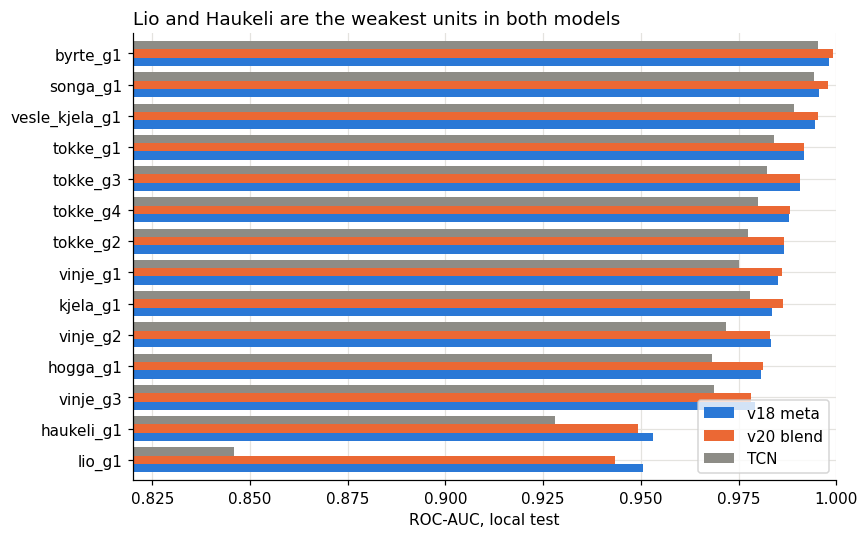

#### How Much Each Generator Relies on the TCN

Similarly, the final predictions for each generator rely on the TCN to a varying degree. While the blending weight is fixed across all generators for Version 20, the meta-model weights in Version 18 differ significantly by unit.

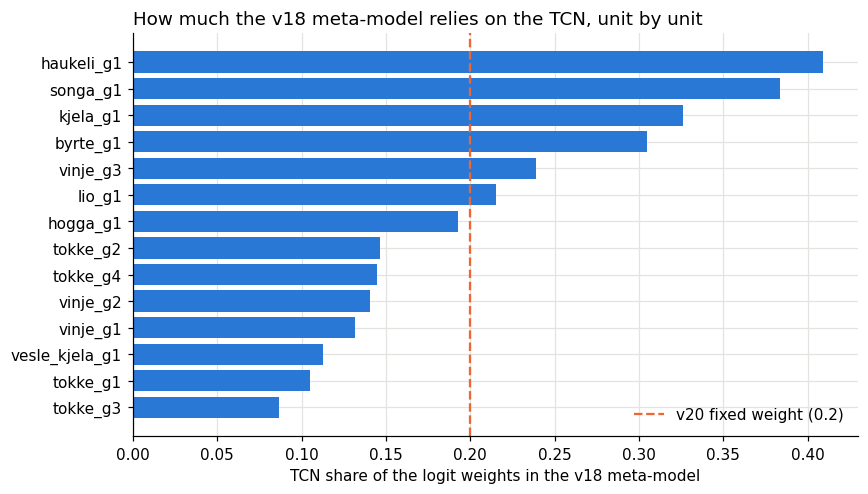

#### Interpreting the Results

To further analyze the results and better understand the models, we focus on the largest facility in the cascade, the Tokke power plant. We first examine the XGBoost model (Version 18).

For the Tokke power plant, the TreeSHAP analysis shows that individual predictions on the log-odds scale are most strongly driven by three features: the Viterbi budget-constrained margin (`vit_budget`), which accounts for start-up and shutdown costs as well as the available weekly water budget; the estimated upstream water release (`up_release`); and the shadow price determined by our LP (`lp_reduced_cost`).

When aggregated by feature group, the five most important groups are, in descending order:
1. Features representing the units' physical behavior (including the Viterbi model).
2. Features describing available weekly water budgets and cost-efficient hours.
3. Features detailing water releases from upstream power plants.
4. Features derived from the Linear Programming (LP) optimization regarding network operation.
5. Features capturing the evolution of electricity prices and water values.

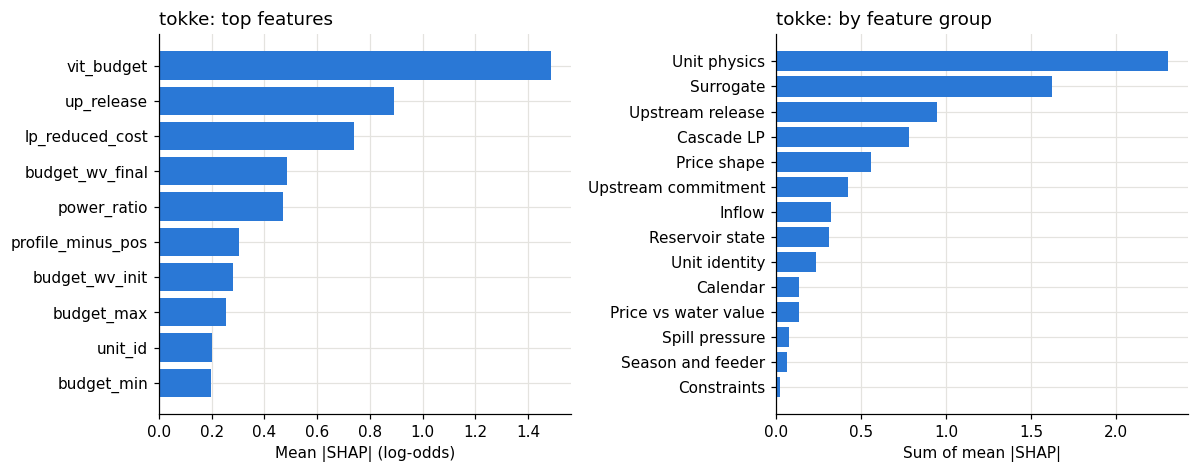

However, when examining the week with the highest prediction error in the test dataset, we observe a pattern caused by this heavy reliance on physical modeling. While our initial analysis suggested that earlier models predicted too frequent switching between operating states, during this particular week, the final model predicts too few shutdowns.

Since Generator 1 was generally predicted to operate before the other generators, we focus our analysis on this unit. The SHAP analysis reveals that features describing the unit's physical behavior—particularly those derived from our Viterbi model—strongly favor continuous operation. As a result, the model consistently predicts that the unit remains operational rather than capturing the actual shutdowns observed during the latter part of the week.

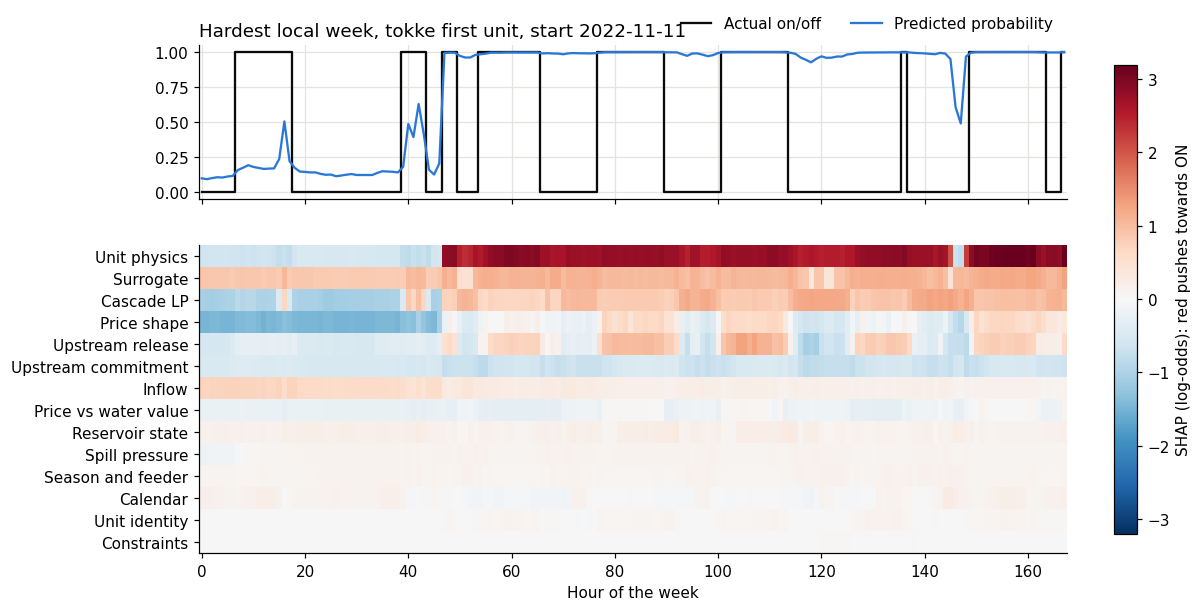

To further investigate this behavior, we examine hour 90 of the previously analyzed week, when the generator is supposed to be shut down but both models incorrectly predict that it remains operational. 

The local SHAP analysis reveals that both models are primarily influenced by features describing the unit's physical behavior, followed by the surrogate model, reservoir state, and Cascade LP features. These feature groups strongly favor operation, outweighing the negative contributions of features such as the electricity price relative to the water value and calendar effects. It appears that the final model does not assign these conflicting signals the appropriate weight, which may stem from either overfitting or an inaccurate representation of the unit's physical behavior during anomalous periods.

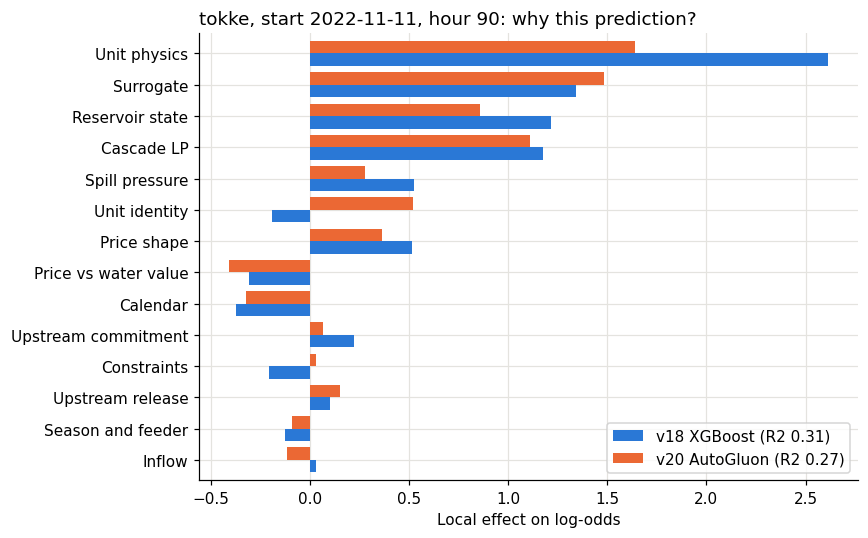

Additionally, during this specific week, the model also incorrectly predicts the total number of active generators running within the plant.

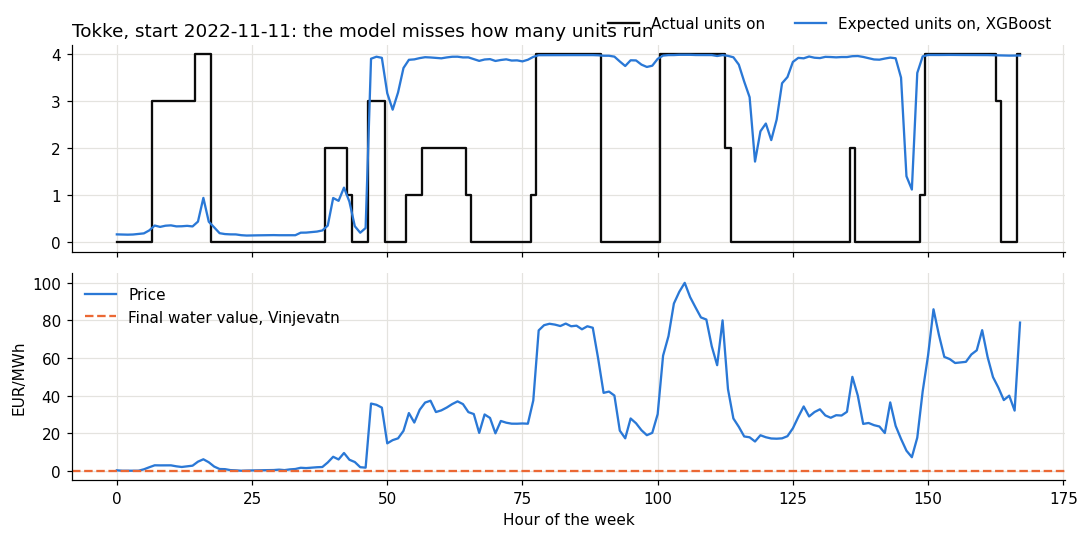

### Feature Sensitivity Analysis

To further investigate how individual features influence the models' predictions, we examine the effect of three important features on the predicted log-odds of operation for the Tokke, Lio, and Haukeli power plants. The plots below show the average effect of varying each feature (blue lines), alongside the individual responses for different observations (grey lines).

Both XGBoost and AutoGluon exhibit similar relationships between the feature values and the predicted commitment decisions. However, XGBoost generally shows a stronger response to changes in these features.

For Tokke, the Viterbi budget feature (`vit_budget`) exhibits a particularly pronounced threshold-like behavior. Around a feature value of zero, the predicted log-odds of operation increase sharply before reaching a plateau. This indicates that both models strongly associate a positive Viterbi budget margin with generator operation. The effect is considerably stronger for XGBoost than for AutoGluon, which may help explain the previously observed tendency to predict continuous operation despite actual shutdowns.

Similar patterns can be observed for Lio and Haukeli. For Lio, the price-related feature (`log_price_wv_source`) shows a gradual increase followed by a plateau, while the LP reduced-cost feature (`lp_reduced_cost`) for Haukeli exhibits a more pronounced increase around zero.

Overall, these results suggest that both models learn similar relationships between the optimization-derived features and generator operation, but differ in their sensitivity. The pronounced threshold behavior, particularly for Tokke, may contribute to the models' difficulties in accurately reproducing short-term switching decisions.

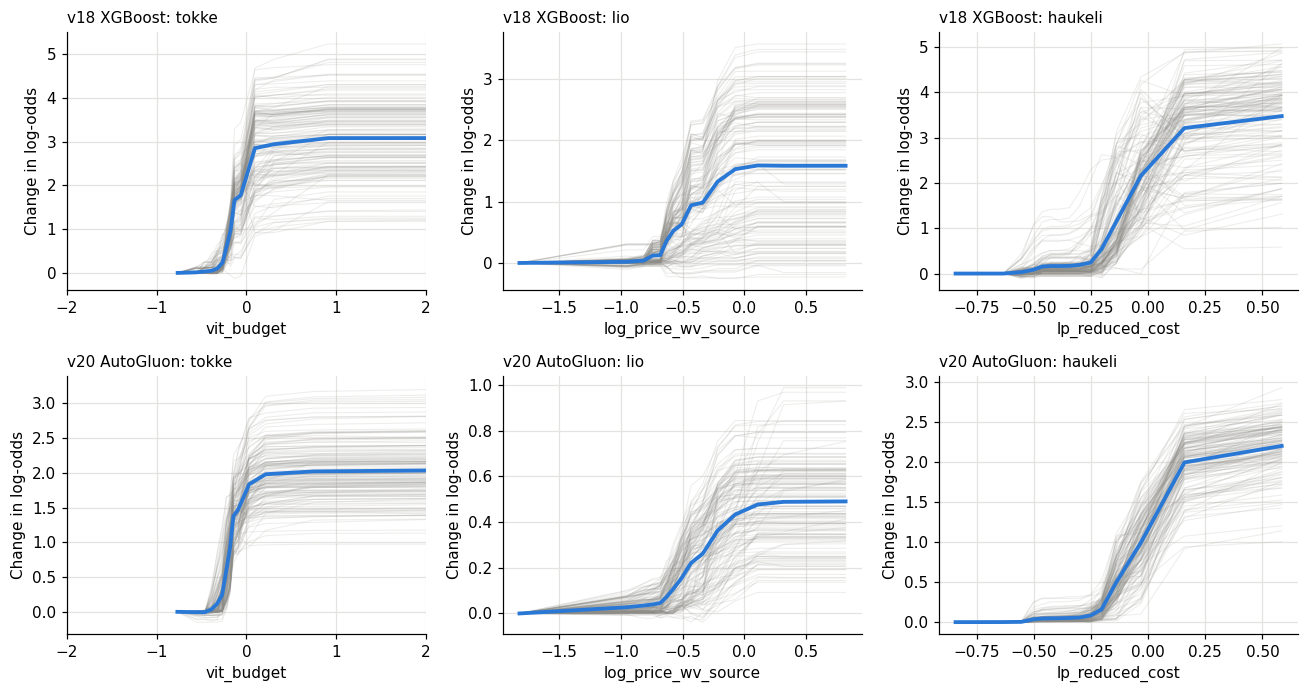

### Evaluating the TCN

When evaluating feature importance for the TCN, the dominant feature groups remain largely consistent with the tree models:
1. Features representing the units' physical behavior (including the Viterbi model).
2. Features describing available weekly water budgets and cost-efficient hours.
3. Features derived from the simple LP regarding network operation.
4. Features capturing the evolution of electricity prices and water values.

Because the neural network evaluates all plants simultaneously, it does not utilize the upstream out-of-fold stacking features (upstream water releases) required by the sequential tree models. As a result, the price versus water value feature group assumes a significantly more important role in the TCN than it does in the tree-based pipelines.

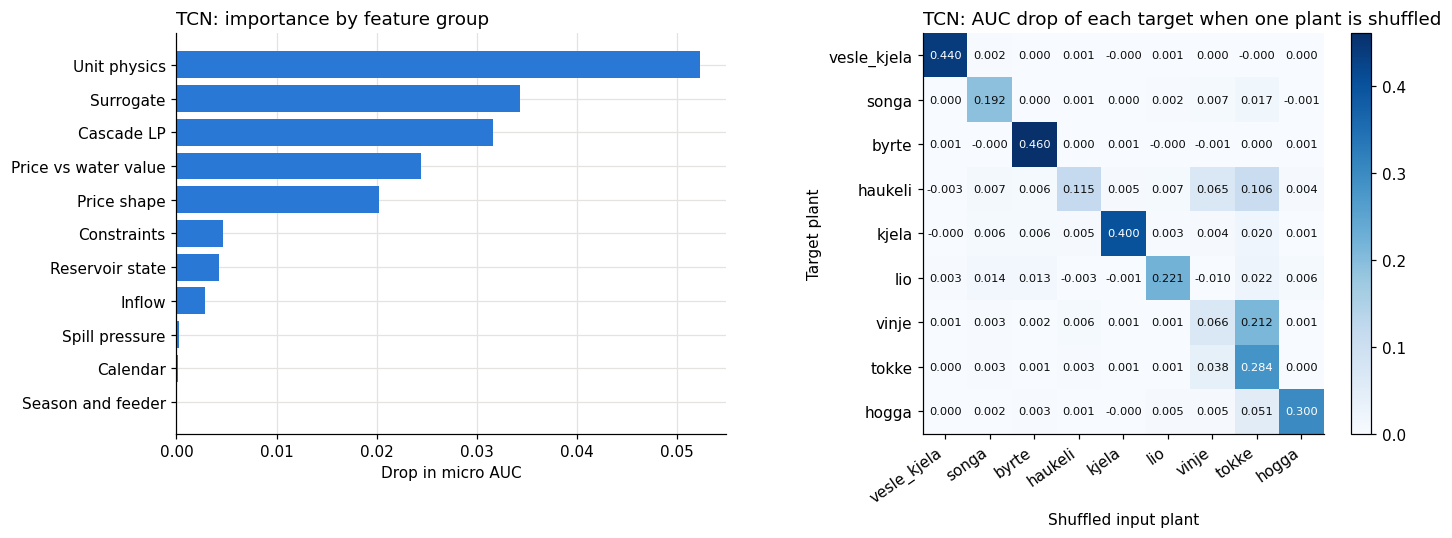

Examining the temporal importance of the input features for the TCN reveals several distinct peaks in the model's sensitivity. Interestingly, the model appears to consider information from both the past and the future in a relatively symmetric manner.

The results show that the model is most sensitive to inputs at the prediction hour itself, with considerably smaller contributions from immediately surrounding hours. However, distinct peaks can also be observed at offsets of approximately ±24, ±48, and ±72 hours, suggesting that the network makes use of recurring daily patterns. Additional minor peaks occur at shorter offsets, particularly around ±4 and ±8 hours, indicating sensitivity to intraday variations.

The peaks at ±24, ±48, and ±72 hours correspond directly to the daily updates of reservoir volumes and water values. Since these variables change only once every 24 hours, focusing on these offsets allows the model to access critical state information from previous and subsequent days. 

Nevertheless, as expected, the model is most sensitive to the input features at the exact prediction hour itself, indicating that current conditions still have the strongest absolute influence on its dispatch predictions.

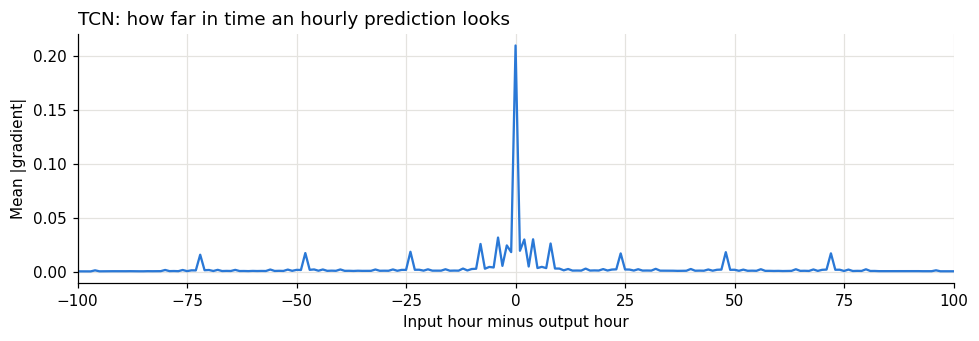

### Model Evaluation and Interpretation Findings

To understand how our models make unit commitment decisions and how much we can trust their scores on unseen data, we applied multiple model interpretation methods, including Permutation Feature Importance, TreeSHAP, Partial Dependence Plots (PDPs), Global Surrogate Decision Trees, and Friedman's H-statistic on our 80/20 split.

#### 1. Feature Importance and Plant-Specific Drivers (Permutation & SHAP)
Comparing the XGBoost (Version 18) and AutoGluon (Version 20) branches shows that different tree architectures learn almost the exact same feature hierarchy:
* **Engineered Features vs. Raw Prices:** Across both the tree models and the TCN, our domain-specific optimization features are much more important than raw electricity price shapes. In the TCN, permuting unit physics drops the ROC-AUC by 0.052, surrogate features by 0.034, and Linear Programming (LP) features by 0.032, whereas permuting the price shape channels only reduces the score by 0.020.
* **Main Drivers by Power Plant:** Permutation importance (measured by the drop in AUC for v18 / v20) reveals that each plant is governed by its own local physical role in the cascade. Upstream plants like Byrte, Vesle Kjela, and Songa are driven primarily by unit physics; Vinje is driven by the spread between price and water value (0.220 / 0.161); Haukeli relies most on the global cascade LP (0.137 / 0.135); and Lio is dominated by environmental flow constraints (0.164 / 0.169).
* **Feature Redundancy (SHAP vs. Permutation):** For multi-unit plants like Tokke, TreeSHAP shows large individual feature contributions to the predicted log-odds, but permuting any single feature group causes only a minor drop in AUC (at most 0.020 in v18 and 0.048 in v20). This happens because our engineered features are highly correlated and compensate for each other when one group is shuffled.
* **Cross-Plant Dependencies in the TCN:** Because the TCN evaluates all plants simultaneously, shuffling the inputs of Tokke reduces the prediction accuracy of Vinje by 0.212 (compared to a 0.066 drop when shuffling Vinje's own inputs) and Haukeli by 0.106 (vs. 0.115 for its own inputs), showing that the network heavily uses downstream demand at Tokke to infer upstream dispatch.

#### 2. Learned Dispatch Rules and Interactions (PDP, Surrogate Trees, & H-Statistic)
Visualizing the marginal effects of the top features confirms that the machine learning models successfully approximate the underlying physical optimization logic:
* **Economic and Optimization Thresholds (PDP):** The Partial Dependence Plots show a sharp step-change in commitment probability near 0 for the Viterbi water budget (`vit_budget`), and a steep increase once the LP shadow price (`lp_reduced_cost`) rises above 0. Similarly, AutoGluon's very first surrogate tree split for Haukeli is `lp_reduced_cost <= 0.00`.
* **Physical Constraint Rules:** For the Lio plant, the global surrogate trees for both v18 and v20 split on `need_release` near $2.3\text{ m}^3/\text{s}$, demonstrating that the models learn to force the generator ON to meet mandatory minimum river flow requirements even during hours when electricity prices are unprofitable.
* **Global Surrogate Approximation & Interactions:** A shallow global surrogate decision tree with just 8 rules is able to explain most of the complex tree ensembles' variance, achieving $R^2$ scores (v18 / v20) of 0.928 / 0.931 for Tokke, 0.887 / 0.917 for Lio, and 0.828 / 0.855 for Haukeli. Furthermore, Friedman's H-statistic shows very little non-additive pairwise interaction on the log-odds scale ($H^2 \le 0.018$), largely because the non-linear physical interactions were already captured during feature engineering by the Surrogate, Viterbi, and LP sub-models.

#### 3. Score Robustness, Regime Shifts, and Limitations
* **Leaderboard Stability:** Version 18 (0.99112) and Version 20 (0.99104) perform almost identically on the Public Leaderboard (2023 data). The 0.00008 difference between them is negligible compared to the natural period-to-period variation observed on our local test set (where splitting the test set into halves yields a median AUC gap of 0.0020 and a maximum gap of 0.0054). Both models also dip in the exact same seasonal quarters (2021Q3 and 2022Q2).
* **Extrapolation vs. Price Volatility in 2023–2024:** Because our local test set (mid-2021 to 2022) covered the European energy crisis, 94.1% of its weekly mean prices fell outside the 2015–2021 training range. In contrast, 0% of the 2023–2024 Kaggle cases fall outside the historical price range, as 2024 quarterly median prices (38–59 EUR/MWh) return closer to pre-crisis levels than 2023 (62–105 EUR/MWh). However, 13.2% of the Kaggle weeks (10.4% in 2023 and 16.1% in 2024) exhibit extreme relative intraday price swings (standard deviation / mean > 0.616), compared to only 0.5% in training and 3.3% in the local test set. In the 19 local test cases with such high volatility, the v20 blend AUC drops to 0.9411.
* **Known Failure Mode:** Error analysis revealed that Tokke's AUC drops from ~0.99 down to 0.9284 (v18) and 0.9499 (v20) whenever the upstream Vinjevatn reservoir's water value falls below 5 EUR/MWh—a condition that occurs in roughly 11% of the Kaggle test cases.
* **Methodological Limitations:** These interpretations describe what the refitted models rely on rather than true physical causality; high feature importance primarily reflects how well a feature approximates the SHOP optimizer. Because many features are correlated, they can share or swap credit between runs (for instance, surrogate splits swapping between `net_head` and `langeidvatn_volume`). Additionally, the TCN's temporal gradient profile naturally peaks at lags 1, 2, 4, 8, 24, 48, and 72, which is an artifact of the chosen dilation factors rather than a market pattern. Finally, because the blending weights and meta-model regularization ($C$) were tuned on the local test set, the local ensemble scores are slightly optimistic.